<a href="https://colab.research.google.com/github/Jeffrey-Huber/Predicting-NBA-Franchise-Players-/blob/main/Project1BrianAndJeff.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Authors

Jeffrey Huber and Brian Nyugen

Project Question: Make a model that predicts who will be "Franchise Player" by the 6th year of their career based on their rookie season.

Project Intro:

The goal of our project is to determine whether a player's early-career (rookie year) NBA stats can be used to predict their performance later in their career (in their prime), specifically whether they'll become a High-level scorer. We'll use regression to predict their 6th season points per game (PPG) and compare different predictors, loss functions, and hyperparameters. Later, we'll use their 6th season PPG to define a franchise-level player and investigate whether early-career statistics can be used to identify these players. We are going to be using stats from 2010-11 season to the 2019-2020 season so we have statistics from the most recent complete decade.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn
import seaborn as sns

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.linear_model import SGDRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.metrics import mean_absolute_error
from sklearn.compose import TransformedTargetRegressor
from sklearn.model_selection import RepeatedKFold, cross_val_score

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Import the dataset
nba = pd.read_csv("players_stats_by_season_full_details(1).csv")

# Confirm that it loaded
print("Dataset dimensions:", nba.shape)
nba.head()

Dataset dimensions: (53949, 34)


,League,Season,Stage,Player,Team,GP,MIN,FGM,FGA,3PM,...,birth_date,height,height_cm,weight,weight_kg,nationality,high_school,draft_round,draft_pick,draft_team
0,NBA,1999 - 2000,Regular_Season,Shaquille O'Neal,LAL,79,3163.0,956,1665,0,...,"Mar 6, 1972",7-1,216.0,325.0,147.0,United States,Robert G. Cole High School,1.0,1.0,Orlando Magic
1,NBA,1999 - 2000,Regular_Season,Vince Carter,TOR,82,3126.0,788,1696,95,...,"Jan 26, 1977",6-6,198.0,220.0,100.0,United States,Mainland High School,1.0,5.0,Golden State Warriors
2,NBA,1999 - 2000,Regular_Season,Karl Malone,UTA,82,2947.0,752,1476,2,...,"Jul 24, 1963",6-9,206.0,265.0,120.0,United States,Summerfield High School,1.0,13.0,Utah Jazz
3,NBA,1999 - 2000,Regular_Season,Allen Iverson,PHI,70,2853.0,729,1733,89,...,"Jun 7, 1975",6-0,183.0,165.0,75.0,United States,Bethel High School,1.0,1.0,Philadelphia Sixers
4,NBA,1999 - 2000,Regular_Season,Gary Payton,SEA,82,3425.0,747,1666,177,...,"Jul 23, 1968",6-4,193.0,180.0,82.0,United States,Skyline High School,1.0,2.0,Seattle SuperSonics


We got our dataset from Kaggle and contains season to season statistics for basketball players in multiple different professional leagues. Each row represents a players' stats from specific seasons and includes info such as their league, season, team, player information, and a lot more. Since our project is focused specifically on NBA players, we're going to filter and subset the players and seasons we need during our cleaning process.

In [ ]:
nba.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53949 entries, 0 to 53948
Data columns (total 34 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   League       53949 non-null  object 
 1   Season       53949 non-null  object 
 2   Stage        53949 non-null  object 
 3   Player       53949 non-null  object 
 4   Team         53938 non-null  object 
 5   GP           53949 non-null  int64  
 6   MIN          53949 non-null  float64
 7   FGM          53949 non-null  int64  
 8   FGA          53949 non-null  int64  
 9   3PM          53949 non-null  int64  
 10  3PA          53949 non-null  int64  
 11  FTM          53949 non-null  int64  
 12  FTA          53949 non-null  int64  
 13  TOV          53949 non-null  int64  
 14  PF           53949 non-null  int64  
 15  ORB          53949 non-null  int64  
 16  DRB          53949 non-null  int64  
 17  REB          53949 non-null  int64  
 18  AST          53949 non-null  int64  
 19  STL 

There are so many different variables in our dataset that it would be hard to explain every single one, so I'll explain some of the important ones that will be popping up throughout our project. Some of the main variables we'll be looking at are GP (Games Played), MIN (Minutes Played), PTS (Points), AST (Assists), REB (Rebounds), STL (Steals), and TOV (Turnovers). There are also other important statistics such as FGM/FGA (Field Goals Made/Attempted), which help measure a player's shooting performance.
GP tells us how many games a player played during a season, with an NBA regular season typically having 82 games. MIN tells us how much time a player spent on the court throughout the season (48 minutes in a game). PTS measures how many points a player scored, while AST and REB help show their contributions outside of just scoring. STL is a defensive statistic, while TOV represents how many times a player lost possession of the ball.

<br>

Although there are many different ways a player can contribute to winning basketball games, our project is specifically focused on scoring. We want to see how well these early-career statistics can help us identify players who will eventually develop into high-level scorers later in their careers.

In [ ]:
nba_cleaning = nba[nba['League'] == 'NBA']

We're only going to be using Regular Season statistics for our project. The main reason we're leaving out Playoff statistics is because not every player makes the Playoffs, and even for the players that do, the amount of games they play can be completely different depending on how far their team goes. One player could only play 4 Playoff games while another could play 20+, giving them very different amounts of opportunities to build up their stats. Using only Regular Season data gives players a more consistent amount of games to compare and makes our data more even.

In [ ]:
nba_cleaning = nba_cleaning[nba_cleaning['Stage'] == 'Regular_Season']

In [ ]:
# Add a temporary column for the start year of the current season
nba_cleaning['current_season_start_year'] = nba_cleaning['Season'].apply(lambda x: int(x.split(' - ')[0]))

# Find the earliest season year for each player within the nba_cleaning dataset
player_min_season_year = nba_cleaning.groupby('Player')['current_season_start_year'].transform('min')

# Calculate Season_Number based on the earliest season in the dataset
nba_cleaning['Season_Number'] = nba_cleaning['current_season_start_year'] - player_min_season_year + 1

# Apply the condition: set 'Season_Number' to NaN for seasons before 2010-2011
nba_cleaning.loc[nba_cleaning['current_season_start_year'] < 2010, 'Season_Number'] = np.nan

# Drop the temporary column
nba_cleaning.drop(columns=['current_season_start_year'], inplace=True)


In [ ]:
nba_cleaning = nba_cleaning[nba_cleaning['Season'].apply(lambda x: 2010 <= int(x.split(' - ')[0]) <= 2020)]
display(nba_cleaning.head())

,League,Season,Stage,Player,Team,GP,MIN,FGM,FGA,3PM,...,height,height_cm,weight,weight_kg,nationality,high_school,draft_round,draft_pick,draft_team,Season_Number
11849,NBA,2010 - 2011,Regular_Season,Kevin Durant,OKC,78,3037.7,711,1538,145,...,6-9,206.0,240.0,109.0,United States,Montrose Christian School,1.0,2.0,Seattle SuperSonics,4.0
11850,NBA,2010 - 2011,Regular_Season,LeBron James,MIA,79,3063.0,758,1484,92,...,6-8,203.0,250.0,113.0,United States,St. Vincent St. Mary High School,1.0,1.0,Cleveland Cavaliers,8.0
11851,NBA,2010 - 2011,Regular_Season,Kobe Bryant,LAL,82,2778.7,740,1639,115,...,6-6,198.0,212.0,96.0,United States,Lower Merion High School,1.0,13.0,Charlotte Hornets,12.0
11852,NBA,2010 - 2011,Regular_Season,Derrick Rose,CHI,81,3025.8,711,1597,128,...,6-3,191.0,200.0,91.0,United States,Simeon Career Academy,1.0,1.0,Chicago Bulls,3.0
11853,NBA,2010 - 2011,Regular_Season,Amar'e Stoudemire,NYK,78,2870.0,744,1482,10,...,6-10,208.0,245.0,111.0,United States,Cypress Creek High School,1.0,9.0,Phoenix Suns,9.0


In [ ]:
nba_cleaning['draft_round'] = nba_cleaning['draft_round'].fillna('Undrafted')
nba_cleaning['draft_round'] = nba_cleaning['draft_round'].astype(str)
nba_cleaning['draft_round'] = pd.Categorical(nba_cleaning['draft_round'])

In [ ]:
nba_cleaning['PPG'] = nba_cleaning['PTS'] / nba_cleaning['GP']
display(nba_cleaning[['Player', 'Season', 'PTS', 'GP', 'PPG']].head())

,Player,Season,PTS,GP,PPG
11849,Kevin Durant,2010 - 2011,2161,78,27.705128
11850,LeBron James,2010 - 2011,2111,79,26.721519
11851,Kobe Bryant,2010 - 2011,2078,82,25.341463
11852,Derrick Rose,2010 - 2011,2026,81,25.012346
11853,Amar'e Stoudemire,2010 - 2011,1971,78,25.269231


We created a new variable called PPG which stands for Points Per Game, it is defined by dividing total points scored in a season by the amount of games played in a season. This is going to be a key variable when it comes to defining what a "Franchise Player" is because great basketball players tend to score a lot of points.

In [ ]:
nba_cleaning

,League,Season,Stage,Player,Team,GP,MIN,FGM,FGA,3PM,...,height_cm,weight,weight_kg,nationality,high_school,draft_round,draft_pick,draft_team,Season_Number,PPG
11849,NBA,2010 - 2011,Regular_Season,Kevin Durant,OKC,78,3037.7,711,1538,145,...,206.0,240.0,109.0,United States,Montrose Christian School,1.0,2.0,Seattle SuperSonics,4.0,27.705128
11850,NBA,2010 - 2011,Regular_Season,LeBron James,MIA,79,3063.0,758,1484,92,...,203.0,250.0,113.0,United States,St. Vincent St. Mary High School,1.0,1.0,Cleveland Cavaliers,8.0,26.721519
11851,NBA,2010 - 2011,Regular_Season,Kobe Bryant,LAL,82,2778.7,740,1639,115,...,198.0,212.0,96.0,United States,Lower Merion High School,1.0,13.0,Charlotte Hornets,12.0,25.341463
11852,NBA,2010 - 2011,Regular_Season,Derrick Rose,CHI,81,3025.8,711,1597,128,...,191.0,200.0,91.0,United States,Simeon Career Academy,1.0,1.0,Chicago Bulls,3.0,25.012346
11853,NBA,2010 - 2011,Regular_Season,Amar'e Stoudemire,NYK,78,2870.0,744,1482,10,...,208.0,245.0,111.0,United States,Cypress Creek High School,1.0,9.0,Phoenix Suns,9.0,25.269231
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
51971,NBA,2019 - 2020,Regular_Season,Matt Dellavedova,CLE,57,820.7,62,175,21,...,193.0,200.0,91.0,Australia,Australian Institute of Sport,Undrafted,NaN,NaN,7.0,3.105263
51972,NBA,2019 - 2020,Regular_Season,Goga Bitadze,IND,54,471.3,70,150,8,...,211.0,245.0,111.0,Georgia,NaN,1.0,18.0,Indiana Pacers,1.0,3.185185
51973,NBA,2019 - 2020,Regular_Season,Nassir Little,POR,48,572.5,65,151,14,...,198.0,220.0,100.0,United States,Orlando Christian Prep High School,1.0,25.0,Portland Trail Blazers,1.0,3.583333
51974,NBA,2019 - 2020,Regular_Season,David Nwaba,BRK,20,268.5,37,71,12,...,193.0,219.0,99.0,United States,University City High School,Undrafted,NaN,NaN,3.0,5.200000


After cleaning our data, our dataset is now focused specifically on the NBA Regular Season players and the seasons that are relevant to our project. We also created a Season Number variable so we can track a player's career based on what year they're in, rather than the actual NBA season they played in. This allows us to more easily show their progression through their career.

In [ ]:
print("Original dataset:", nba.shape)
print("Cleaned dataset:", nba_cleaning.shape)

Original dataset: (53949, 34)
Cleaned dataset: (2399, 36)


Through cleaning we removed the majority of rows from the set, this is notable going forward that we have a much smaller sample size of rows. 53949 rows originally vs 2399 rows in the final version.

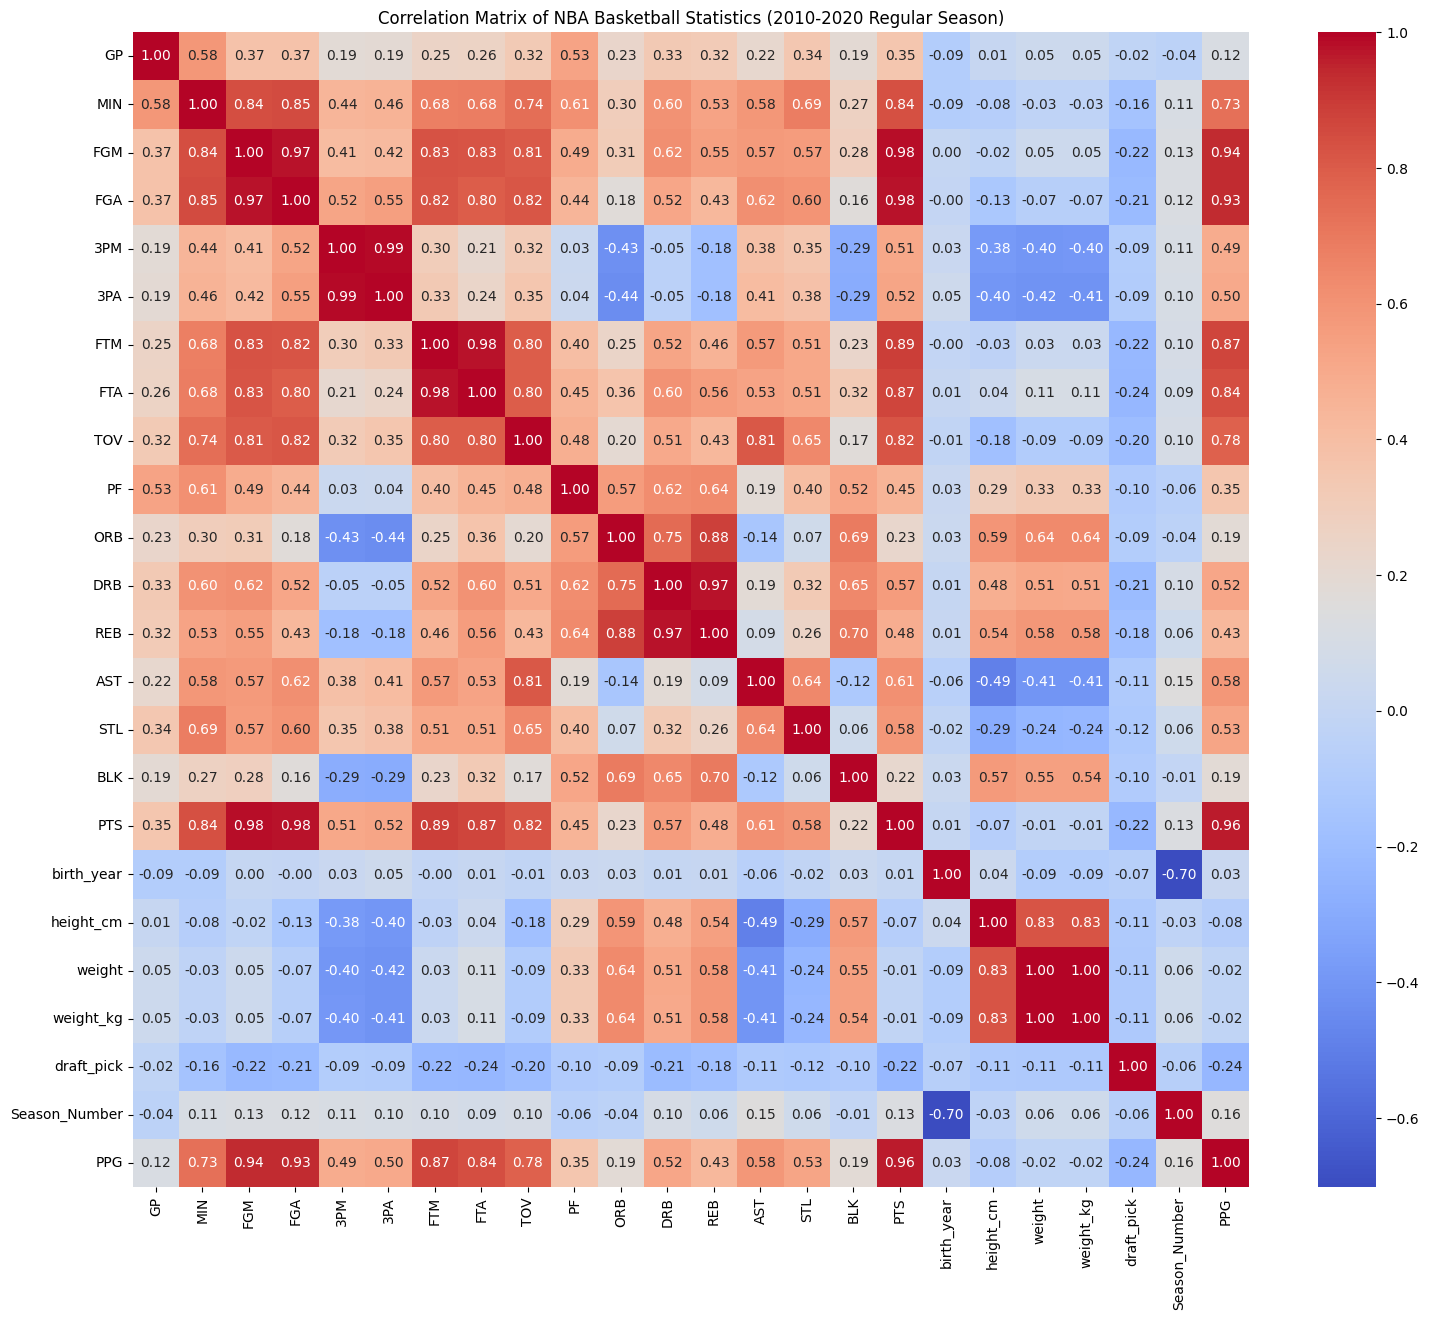

In [ ]:
# Select only numerical columns for correlation calculation
numerical_cols = nba_cleaning.select_dtypes(include=np.number).columns
correlation_matrix = nba_cleaning[numerical_cols].corr()

# Plotting the correlation heatmap
plt.figure(figsize=(18, 15))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix of NBA Basketball Statistics (2010-2020 Regular Season)')
plt.show()

As we looked through our correlation matrix, we can see that a lot of our offensive statistics have a strong correlation with each other. This makes sense since stats like points, field goals made, field goals attempted, and minutes played are all connected to how involved a player is during a game, specifically when they're involved on the offensive side of it. We can also see that some variables like height and weight don't have as strong of a relationship with PPG. It's important for us to know this for our model because we don't want to throw every variable into it causing the model to become over complicated, especially if multiple variables are giving us similar information.

### Correlation Plots with PPG

Earlier in our cleaning process, we created PPG (Points Per Game), which is an important variable for our project. PPG essentially represents the average number of points a player scores per game in a season. It allows us to compare scoring performance between players more evenly than using total points and see how effective they are on a larger scale.

<br>

A player who plays more games has more opportunities to increase their total points, while PPG takes the number of games played into account. This can also help reduce the effect of potential outliers in a player's total points caused by them missing a large number of games. For instance, if a star player gets sick, injured, or has a family issue and misses games during a season, their total points would naturally be lower even though their scoring performance and importance in the games they actually played in, may still be high.

<br>

Since our project is focused on predicting which players will develop into high-level scorers, PPG will be one of our most important variables. Looking at the distribution of PPG allows us to see the typical scoring range within our dataset and how common higher-scoring players are.

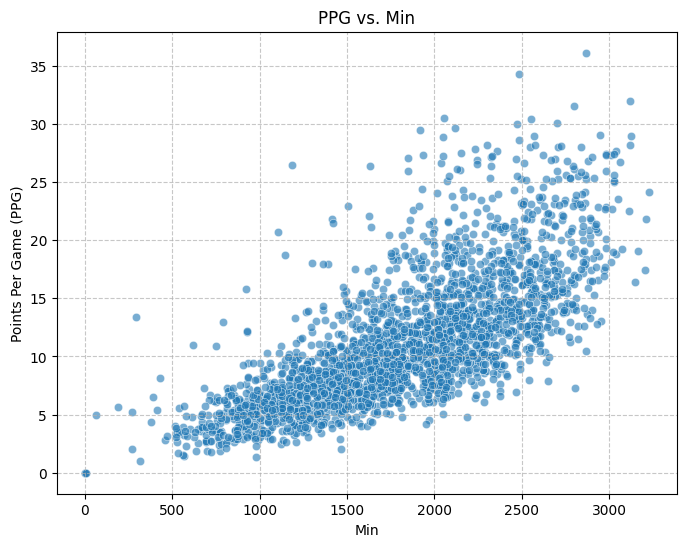

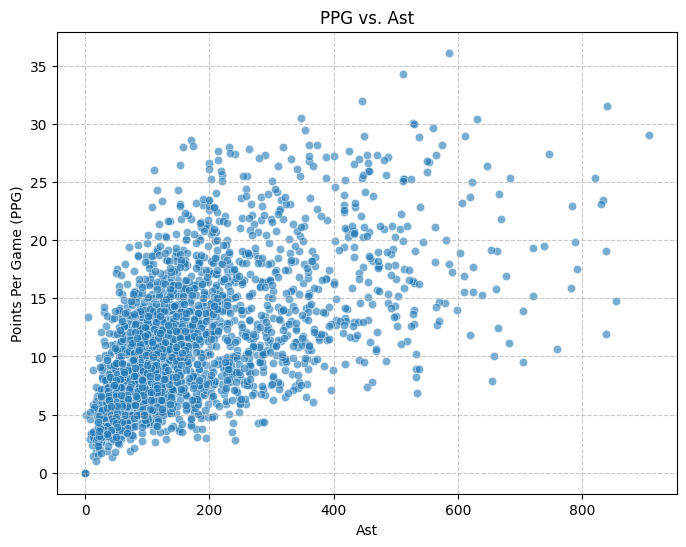

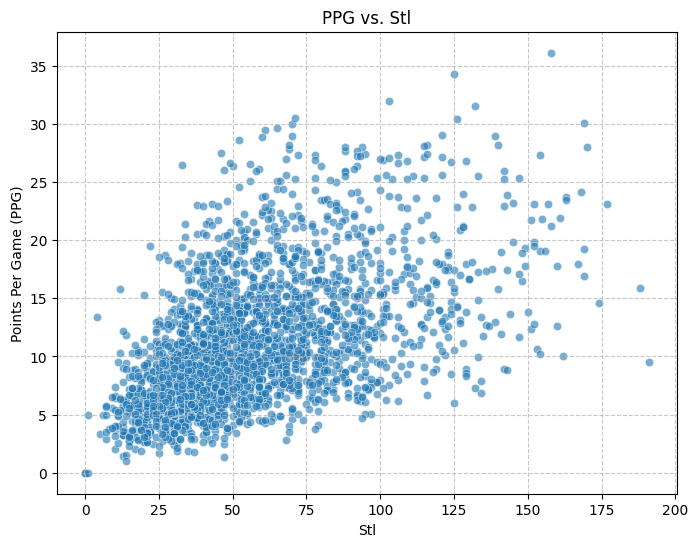

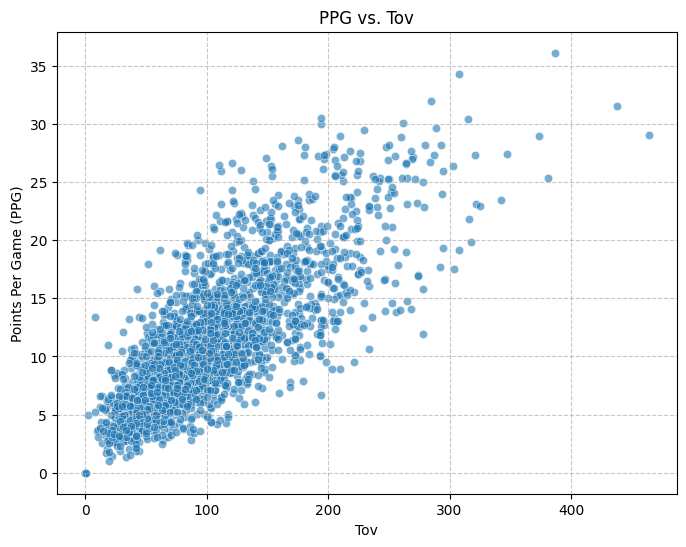

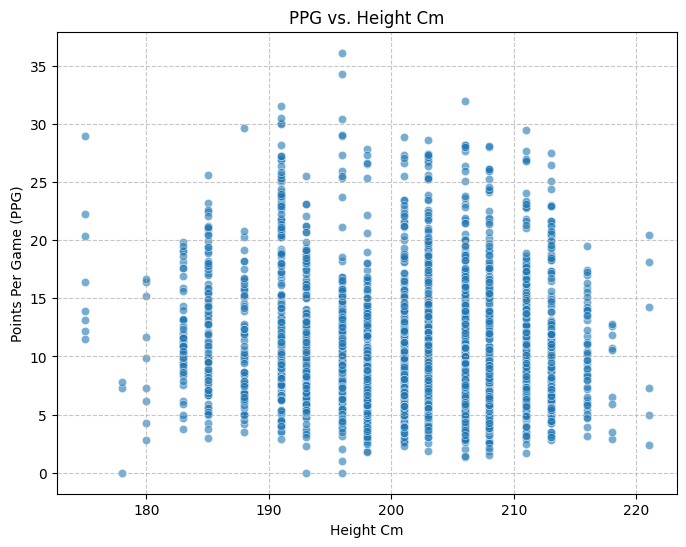

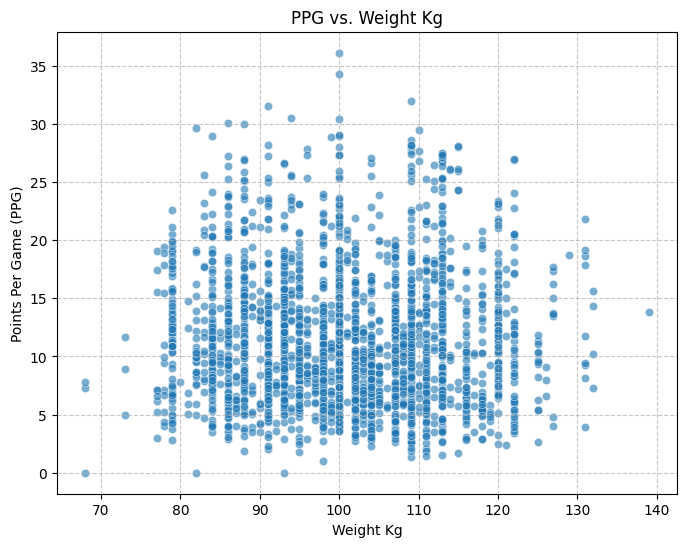

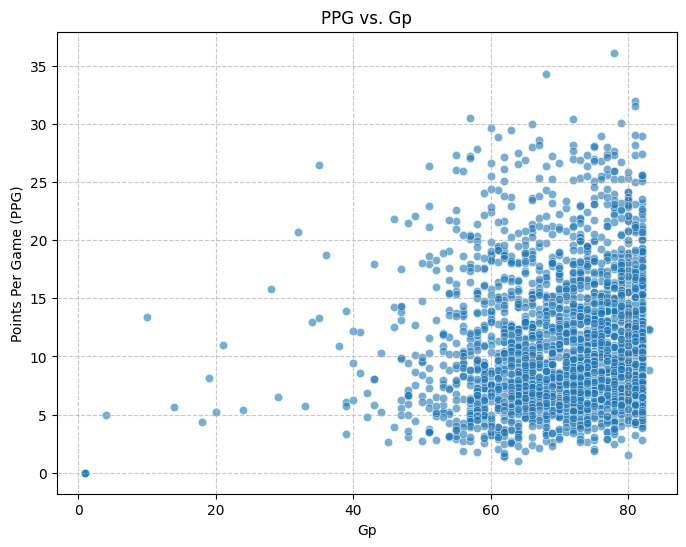

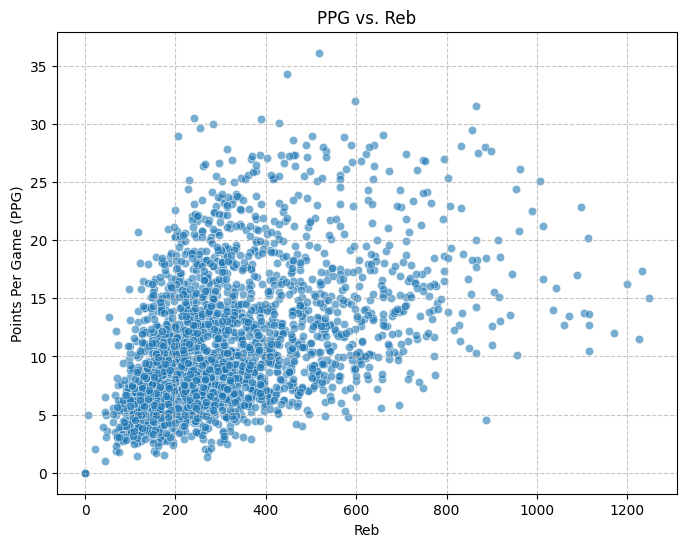

In [ ]:
features_to_plot = ['MIN', 'AST', 'STL', 'TOV', 'height_cm', 'weight_kg', 'GP', "REB"]

for feature in features_to_plot:
    plt.figure(figsize=(8, 6))
    sns.scatterplot(x=feature, y='PPG', data=nba_cleaning, alpha=0.6)
    plt.title(f'PPG vs. {feature.replace("_", " ").title()}')
    plt.xlabel(feature.replace("_", " ").title())
    plt.ylabel('Points Per Game (PPG)')
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.show()

PPG vs Min.
From the graph, we can see a strong positive relationship between minutes played and PPG. As a player gets more minutes, their PPG generally increases as well. This makes sense when we think about it in a real life scenario. As players receive more playing time, it most likely means they have a larger role on their team, more opportunities to score, and more impact as a player in general. However, minutes played does not necessarily mean that a player is better. There are still players with similar minutes played that have very different PPG, so minutes should not be the only variable we use when predicting a player's future PPG.

<br>

PPG vs Assist
From this graph as well, we can see another positive relationship between assists and PPG. As assists increase, PPG generally increases as well. It may be because players who assist tend to have the ball in their hands more often meaning they have a larger role on their team. Larger role with more ball time may in turn mean more PPG. However, the points become more spread out as assists increase, showing that having more assists does not always mean a player will score more points. This could still make assists a useful variable when predicting a player's future PPG.

<br>

PPG vs TOV
Another graph that shows a strong positive relationship between turnovers and PPG. In real life this may be a weird statistic because players who have the ball more tend to have a larger TOV. Then the theoretical relationship we thought of earlier, more ball time may mean more PPG, this could make turnovers another useful variable within our model.

<br>

PPG vs Height CM
It looks like there isn't a strong relationship between height and PPG. Players around the same height can have very different PPG, and being taller doesn't necessarily mean that a player will score more points. However, height could still be useful in our model because it gives us information about the physical characteristics of a player that can help us cover a wider range of info besides just performance statistics. *We can later test whether including height improves our model's predictions.*

<br>

PPG VS Weight KG
A little surprising, there doesn't seem to be a strong relationship between weight and PPG. Players around the same weight can have completely different PPG. In context though, being heavier or lighter doesn't necessarily mean that a player will score more. However, similar to height, weight gives us another type of info about the player outside of their performance statistics. My prediction is that we'll only be using just Height or just Weight within our model.

<br>

PPG VS GP
This is one relationship that surprised me a little but makes sense in the grand scope of things. There doesn't actually seem to be a strong relationship between games played and PPG. Most players play around 60-82 games and within that range, we can see players averaging anywhere from 5 to 35 points. This makes sense when you take into account that basketball isn't all about scoring points. However, PPG does help us identify who are potential franchise players. It seems likely that games played won't be a very useful variable given that most players will be playing around 60-82 games. However, one can argue that franchise players should be consistently available and playing throughout the season since they're the top scorers of their team, so we will test this variable in our model and see if it actually improves our predictions.

<br>

PPG Vs REB
Lastly for rebounds, we can see a positive relationship between rebounds and PPG, but the relationship isn't as strong compared to some of the other variables. As rebounds increase, PPG generally increases as well, but there are still players with similar amounts of rebounds that have very different PPG. This makes sense in a real life scenario because rebounding and scoring are different parts of a player's game. Even though rebounds may not be the strongest predictor of PPG by itself, it can still give our model more information about a player's overall performance and impact on the court.



In [ ]:
# Correlation coefficients between PPG and the variables shown above
ppg_correlations = nba_cleaning[
    ['PPG', 'MIN', 'AST', 'STL', 'TOV', 'height_cm', 'weight_kg', 'GP', 'REB']
].corr()['PPG'].drop('PPG').sort_values(ascending=False)

print("Correlation Coefficients with PPG:")
print(ppg_correlations)

Correlation Coefficients with PPG:
TOV          0.780596
MIN          0.733755
AST          0.582307
STL          0.527588
REB          0.434135
GP           0.122064
weight_kg   -0.021959
height_cm   -0.079152
Name: PPG, dtype: float64


After looking at our scatterplots and correlation coefficients, we can see that some variables have a much stronger relationship with PPG than others. TOV had the strongest positive correlation with PPG at around 0.78, followed by MIN at around 0.73. AST and STL also showed moderate positive correlations at around 0.58 and 0.53. This makes sense since players who are more involved in a game will usually have more opportunities to score, but may also have more opportunities to get assists, steals, and even turnovers.

<br>

On the other hand, GP had a much weaker correlation of around 0.12, while weight and height were both close to 0. This shows us that just being taller, heavier, or playing more games doesn't actually have much of a linear relationship with how many points a player scores per game. These correlations give us a better idea of which variables may be useful when we start building our models, but we'll still test different combinations to see which variables actually help our predictions.

Model Building/Testing:

Our goal is to use a player's Season 1 statistics to predict their PPG in Season 6. To do this, we'll first create a new dataset that matches each player's Season 1 statistics with their Season 6 PPG. Season 6 PPG will be our target variable, while the Season 1 statistics will be the predictor variables we'll be testing and trying different variations for in our models.


Since many of our variables have a strong linear relationship with PPG, our first modeling strategy is going to be regression-based classification.

In [ ]:
features_cols = ['GP', 'MIN', 'FGM', 'FGA', '3PM', '3PA', 'FTM', 'FTA', 'TOV', 'PF', 'ORB', 'DRB', 'REB', 'AST', 'STL', 'BLK', 'PTS', 'PPG', 'height_cm', 'weight']

# Filter for Season_Number 1 data with all specified features
season1_data = nba_cleaning[nba_cleaning['Season_Number'] == 1][['Player'] + features_cols]
season1_data = season1_data.rename(columns={col: f'Season_1_{col}' for col in features_cols})

# Filter for Season_Number 6 data for points (target variable)
season6_pts_expanded = nba_cleaning[nba_cleaning['Season_Number'] == 6][['Player', 'PPG']].rename(columns={'PPG': 'Season_6_PPG'})

# Merge the two DataFrames on 'Player'
prediction_df_expanded = pd.merge(season1_data, season6_pts_expanded, on='Player', how='inner')

# Display the head of the new DataFrame
display(prediction_df_expanded.head())

print(prediction_df_expanded.info())

,Player,Season_1_GP,Season_1_MIN,Season_1_FGM,Season_1_FGA,Season_1_3PM,Season_1_3PA,Season_1_FTM,Season_1_FTA,Season_1_TOV,...,Season_1_DRB,Season_1_REB,Season_1_AST,Season_1_STL,Season_1_BLK,Season_1_PTS,Season_1_PPG,Season_1_height_cm,Season_1_weight,Season_6_PPG
0,DeMarcus Cousins,81,2309.4,432,1004,3,18,276,402,268,...,482,699,204,85,68,1143,14.111111,211.0,270.0,26.892308
1,Greg Monroe,80,2221.8,303,550,0,1,145,233,81,...,353,601,105,92,45,751,9.387500,211.0,265.0,15.316456
2,Wesley Johnson,79,2069.3,271,682,103,289,64,92,95,...,189,240,148,58,54,709,8.974684,201.0,215.0,6.862500
3,Evan Turner,78,1797.4,225,529,14,44,101,125,80,...,264,306,159,49,14,565,7.243590,201.0,220.0,10.543210
4,Dante Cunningham,78,1636.9,218,472,1,13,45,62,51,...,181,277,43,54,43,482,6.179487,203.0,230.0,6.050000


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 82 entries, 0 to 81
Data columns (total 22 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Player              82 non-null     object 
 1   Season_1_GP         82 non-null     int64  
 2   Season_1_MIN        82 non-null     float64
 3   Season_1_FGM        82 non-null     int64  
 4   Season_1_FGA        82 non-null     int64  
 5   Season_1_3PM        82 non-null     int64  
 6   Season_1_3PA        82 non-null     int64  
 7   Season_1_FTM        82 non-null     int64  
 8   Season_1_FTA        82 non-null     int64  
 9   Season_1_TOV        82 non-null     int64  
 10  Season_1_PF         82 non-null     int64  
 11  Season_1_ORB        82 non-null     int64  
 12  Season_1_DRB        82 non-null     int64  
 13  Season_1_REB        82 non-null     int64  
 14  Season_1_AST        82 non-null     int64  
 15  Season_1_STL        82 non-null     int64  
 16  Season_1_B

In [ ]:
first_model_data = prediction_df_expanded[['Season_1_PPG', 'Season_6_PPG']].dropna()
X = first_model_data[['Season_1_PPG']]
y = first_model_data["Season_6_PPG"]

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42
)

In [ ]:
new_linreg_gd_model = make_pipeline(
    StandardScaler(),
    SGDRegressor(
        loss='squared_error',
        max_iter=1000,
        eta0=0.01,
        learning_rate='constant',
        random_state=42,
        verbose=1
    )
)

For our first model, we wanted to create a baseline. So we thought a very basic baseline to use would be a classic squared_error with a learning rate of 0.01. We also set our iterations to 1000 because we thought this could be a good converging point for our model. These settings give us a starting point that we can later compare to other hyperparameters to see if we can improve our model.

In [ ]:
new_linreg_gd_model.fit(X_train, y_train)
# X: Season 1 PPG
# y: Season 6 PPG

-- Epoch 1
Norm: 1.18, NNZs: 1, Bias: 5.701756, T: 57, Avg. loss: 67.692952
Total training time: 0.00 seconds.
-- Epoch 2
Norm: 1.84, NNZs: 1, Bias: 8.870736, T: 114, Avg. loss: 31.282887
Total training time: 0.00 seconds.
-- Epoch 3
Norm: 2.20, NNZs: 1, Bias: 10.600955, T: 171, Avg. loss: 20.004200
Total training time: 0.00 seconds.
-- Epoch 4
Norm: 2.36, NNZs: 1, Bias: 11.604475, T: 228, Avg. loss: 16.417157
Total training time: 0.00 seconds.
-- Epoch 5
Norm: 2.52, NNZs: 1, Bias: 12.140116, T: 285, Avg. loss: 15.272537
Total training time: 0.00 seconds.
-- Epoch 6
Norm: 2.51, NNZs: 1, Bias: 12.417773, T: 342, Avg. loss: 14.899789
Total training time: 0.00 seconds.
-- Epoch 7
Norm: 2.51, NNZs: 1, Bias: 12.627110, T: 399, Avg. loss: 14.789037
Total training time: 0.00 seconds.
-- Epoch 8
Norm: 2.52, NNZs: 1, Bias: 12.693415, T: 456, Avg. loss: 14.736918
Total training time: 0.00 seconds.
-- Epoch 9
Norm: 2.62, NNZs: 1, Bias: 12.894470, T: 513, Avg. loss: 14.702060
Total training time: 

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('sgdregressor',
                 SGDRegressor(learning_rate='constant', random_state=42,
                              verbose=1))])

In [ ]:
new_y_pred_train = new_linreg_gd_model.predict(X_train)
new_y_pred_test  = new_linreg_gd_model.predict(X_test)

# r-squared and adjusted r-squared
new_r2_train = r2_score(y_train, new_y_pred_train)
new_r2_test  = r2_score(y_test, new_y_pred_test)

print(f"Train R²: {new_r2_train:.4f}")
print(f"Test  R²: {new_r2_test:.4f}")
#Even for baseline, theres numbers were too small so we decided to change our test data to 20%

Train R²: 0.1974
Test  R²: 0.4501


In [ ]:
print("Number of predictors:", X_train.shape[1])
print("Training observations:", X_train.shape[0])
print("Testing observations:", X_test.shape[0])

Number of predictors: 1
Training observations: 57
Testing observations: 25


Our baseline model had a training R² of around 0.20 and a testing R² of around 0.45. The low training R² tells us that our current model isn't actually explaining a large amount of the variation in a player's Season 6 PPG. Since we're only using one predictor in this model, there's still a lot of information about a player's future scoring performance that the model isn't taking into account which could tell us why it was so low.

<br>

Looking in a bit deeper because we were a little confused on why our training and testing were so different, we realized we only had 82 observations in our dataset, with 57 being used for training and 25 for testing. This is because we can only model around players whose first season and sixth season are both in our data range. Since our testing set is relatively small, the players that randomly ended up in the testing set may have had a stronger relationship between our predictor and Season 6 PPG than the players in the training set. This could explain why our model performed better on the testing data even though it wasn't trained on it.

In [ ]:
coefficients = new_linreg_gd_model.named_steps['sgdregressor'].coef_

coef_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Coefficient': coefficients
})

coef_df = coef_df.sort_values('Coefficient', ascending=False)
coef_df

,Feature,Coefficient
0,Season_1_PPG,2.64436


Before going into more testing, we wanted to see the coefficients for the variables we had chosen. Since this first model only uses Season 1 PPG as a predictor, it only has one beta coefficient. Looking at the table above, Season 1 PPG had a positive beta coefficient of around 2.64. This makes sense when we look back at our correlation matrix and scatterplots where we saw that PPG had a relationship with scoring performance. The positive beta coefficient also tells us that as Season 1 PPG increases, our model generally predicts a higher Season 6 PPG.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

In [ ]:
new_linreg_gd_model = make_pipeline(
    StandardScaler(),
    SGDRegressor(
        loss='squared_error',
        max_iter=1000,
        eta0=0.01,
        learning_rate='constant',
        random_state=42,
        verbose=1
    )
)

In [ ]:
new_linreg_gd_model.fit(X_train, y_train)

# X: Season 1 PPG
# y: Season 6 PPG

-- Epoch 1
Norm: 1.45, NNZs: 1, Bias: 6.255743, T: 65, Avg. loss: 64.979167
Total training time: 0.00 seconds.
-- Epoch 2
Norm: 2.26, NNZs: 1, Bias: 9.516635, T: 130, Avg. loss: 27.729454
Total training time: 0.00 seconds.
-- Epoch 3
Norm: 2.62, NNZs: 1, Bias: 11.216903, T: 195, Avg. loss: 17.775851
Total training time: 0.00 seconds.
-- Epoch 4
Norm: 2.84, NNZs: 1, Bias: 12.168866, T: 260, Avg. loss: 15.116211
Total training time: 0.00 seconds.
-- Epoch 5
Norm: 2.91, NNZs: 1, Bias: 12.415058, T: 325, Avg. loss: 14.486779
Total training time: 0.00 seconds.
-- Epoch 6
Norm: 3.01, NNZs: 1, Bias: 12.547514, T: 390, Avg. loss: 14.370245
Total training time: 0.00 seconds.
-- Epoch 7
Norm: 2.97, NNZs: 1, Bias: 12.739241, T: 455, Avg. loss: 14.339567
Total training time: 0.00 seconds.
-- Epoch 8
Norm: 2.97, NNZs: 1, Bias: 12.772307, T: 520, Avg. loss: 14.291432
Total training time: 0.00 seconds.
-- Epoch 9
Norm: 3.05, NNZs: 1, Bias: 12.773146, T: 585, Avg. loss: 14.295194
Total training time: 

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('sgdregressor',
                 SGDRegressor(learning_rate='constant', random_state=42,
                              verbose=1))])

In [ ]:
new_y_pred_train = new_linreg_gd_model.predict(X_train)
new_y_pred_test  = new_linreg_gd_model.predict(X_test)

# r-squared and adjusted r-squared
new_r2_train = r2_score(y_train, new_y_pred_train)
new_r2_test  = r2_score(y_test, new_y_pred_test)

print(f"Train R²: {new_r2_train:.4f}")
print(f"Test  R²: {new_r2_test:.4f}")

Train R²: 0.2465
Test  R²: 0.4552


In [ ]:
print(f"Training R²: {r2_score(y_train, new_linreg_gd_model.predict(X_train)):.4f}")
print(f"Testing R²: {r2_score(y_test, new_linreg_gd_model.predict(X_test)):.4f}")

print(f"Training MSE: {mean_squared_error(y_train, new_linreg_gd_model.predict(X_train)):.2f}")
print(f"Testing MSE: {mean_squared_error(y_test, new_linreg_gd_model.predict(X_test)):.2f}")

Training R²: 0.2465
Testing R²: 0.4552
Training MSE: 28.17
Testing MSE: 38.48


Looking at our new results, we believe this is a better baseline to use. Our training R² increased to around 0.25 compared to around 0.20 in our previous model. This means that our new model is able to explain slightly more of the variation in Season 6 PPG than our previous baseline. Although an increase of around 5% isn't the craziest improvement, it does show that the changes we made to our model helped improve its fit to the training data.

<br>

To look even deeper, our testing R² stayed around 0.46 and there is still a pretty large gap between our training and testing R². Our training MSE was 28.17 compared to a testing MSE of 38.48, showing that our model is making larger prediction errors on the testing data.

<br>

Even though we do believe this gives us a slightly better baseline to work from, there is still a lot of room for us to improve the model.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

In [ ]:
new_linreg_gd_model = make_pipeline(
    StandardScaler(),
    SGDRegressor(
        loss='squared_error',
        max_iter=1000,
        eta0=0.05,
        learning_rate='constant',
        random_state=42,
        verbose=1
    )
)

In [ ]:
new_linreg_gd_model.fit(X_train, y_train)


-- Epoch 1
Norm: 2.51, NNZs: 1, Bias: 12.745863, T: 65, Avg. loss: 30.630023
Total training time: 0.00 seconds.
-- Epoch 2
Norm: 3.27, NNZs: 1, Bias: 13.167517, T: 130, Avg. loss: 14.995652
Total training time: 0.00 seconds.
-- Epoch 3
Norm: 3.18, NNZs: 1, Bias: 13.160372, T: 195, Avg. loss: 14.940096
Total training time: 0.00 seconds.
-- Epoch 4
Norm: 2.87, NNZs: 1, Bias: 14.162679, T: 260, Avg. loss: 14.733260
Total training time: 0.00 seconds.
-- Epoch 5
Norm: 2.79, NNZs: 1, Bias: 11.908849, T: 325, Avg. loss: 14.499163
Total training time: 0.00 seconds.
-- Epoch 6
Norm: 3.46, NNZs: 1, Bias: 11.939457, T: 390, Avg. loss: 14.928286
Total training time: 0.00 seconds.
-- Epoch 7
Norm: 2.26, NNZs: 1, Bias: 13.069271, T: 455, Avg. loss: 15.082249
Total training time: 0.00 seconds.
-- Epoch 8
Norm: 2.60, NNZs: 1, Bias: 12.752833, T: 520, Avg. loss: 14.704625
Total training time: 0.00 seconds.
-- Epoch 9
Norm: 3.62, NNZs: 1, Bias: 12.079933, T: 585, Avg. loss: 14.883957
Total training time

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('sgdregressor',
                 SGDRegressor(eta0=0.05, learning_rate='constant',
                              random_state=42, verbose=1))])

In [ ]:
new_y_pred_train = new_linreg_gd_model.predict(X_train)
new_y_pred_test  = new_linreg_gd_model.predict(X_test)

# r-squared and adjusted r-squared
new_r2_train = r2_score(y_train, new_y_pred_train)
new_r2_test  = r2_score(y_test, new_y_pred_test)

print(f"Train R²: {new_r2_train:.4f}")
print(f"Test  R²: {new_r2_test:.4f}")
#This is better for us now as a baseline

Train R²: 0.2110
Test  R²: 0.4673


For this model, we wanted to see what would happen if we increased our learning rate from 0.01 to 0.05 while keeping the rest of our model mostly the same. Looking at our results, our training R² actually decreased from around 0.25 to 0.21, while our testing R² slightly increased from around 0.46 to 0.47. We decided that increasing the learning rate didn't really do much to improve our model and that the learning rate as is, is good enough since it does a better job with the training set.

<br>

Because changing our learning rate didn't give us much improvement, we wanted to now test and see whether using more of our Season 1 variables can help predict Season 6 PPG. Instead of using every variable available in our original dataset, we're focusing on the main basketball statistics we explored earlier such as PPG, MIN, AST, STL, TOV, REB, and GP, along with height and weight.

<br>

Some of these variables showed stronger relationships with PPG in our earlier correlation analysis, while others showed weaker relationships. By testing them together, we want to see whether combining different info about a player's rookie season can explain more of their future scoring performance than Season 1 PPG by itself. (which it most probably will).

In [ ]:
second_model = prediction_df_expanded[['Season_1_PPG','Season_1_MIN', 'Season_1_AST', 'Season_1_STL', 'Season_1_TOV', "Season_1_height_cm", "Season_1_weight", 'Season_1_GP', 'Season_1_REB', 'Season_6_PPG']].dropna()
X = second_model[['Season_1_PPG','Season_1_MIN', 'Season_1_AST', 'Season_1_STL', 'Season_1_TOV', "Season_1_height_cm", "Season_1_weight", 'Season_1_GP', 'Season_1_REB']]
y = second_model["Season_6_PPG"]

We decided to continue training on our 80-20 training/testing split for this model. Since our dataset is relatively small now after subsetting our data (82 rows), we wanted to keep a larger portion of our observations in the training set so the model has more data to learn from. While at the same time, keeping 20% for testing still gives us a decent sized separate group of players that the model hasn't seen before, allowing us to evaluate how well it performs on new data.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

In [ ]:
new_linreg_gd_model = make_pipeline(
    StandardScaler(),
    SGDRegressor(
        loss='squared_error',
        max_iter=1000,
        eta0=0.01,
        learning_rate='constant',
        random_state=42,
        verbose=1
    )
)

In [ ]:
new_linreg_gd_model.fit(X_train, y_train)

# X: Season 1 PPG, Season 1 MIN, Season 1 AST, Season 1 STL, Season 1 TOV, Season 1 height_cm, Season 1 weight, Season 1 GP, Season 1 REB
# y: Season 6 PPG

-- Epoch 1
Norm: 1.36, NNZs: 9, Bias: 6.429542, T: 65, Avg. loss: 67.754342
Total training time: 0.00 seconds.
-- Epoch 2
Norm: 2.05, NNZs: 9, Bias: 9.648643, T: 130, Avg. loss: 27.508045
Total training time: 0.00 seconds.
-- Epoch 3
Norm: 2.31, NNZs: 9, Bias: 11.313760, T: 195, Avg. loss: 17.849965
Total training time: 0.00 seconds.
-- Epoch 4
Norm: 2.63, NNZs: 9, Bias: 12.191595, T: 260, Avg. loss: 15.040870
Total training time: 0.00 seconds.
-- Epoch 5
Norm: 2.82, NNZs: 9, Bias: 12.425274, T: 325, Avg. loss: 14.343270
Total training time: 0.00 seconds.
-- Epoch 6
Norm: 3.09, NNZs: 9, Bias: 12.562150, T: 390, Avg. loss: 14.047223
Total training time: 0.00 seconds.
-- Epoch 7
Norm: 3.09, NNZs: 9, Bias: 12.769373, T: 455, Avg. loss: 13.969129
Total training time: 0.00 seconds.
-- Epoch 8
Norm: 3.24, NNZs: 9, Bias: 12.845384, T: 520, Avg. loss: 13.831659
Total training time: 0.00 seconds.
-- Epoch 9
Norm: 3.46, NNZs: 9, Bias: 12.812007, T: 585, Avg. loss: 13.796299
Total training time: 

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('sgdregressor',
                 SGDRegressor(learning_rate='constant', random_state=42,
                              verbose=1))])

In [ ]:
new_y_pred_train = new_linreg_gd_model.predict(X_train)
new_y_pred_test = new_linreg_gd_model.predict(X_test)

# R-squared
new_r2_train = r2_score(y_train, new_y_pred_train)
new_r2_test = r2_score(y_test, new_y_pred_test)

print(f"Train R²: {new_r2_train:.4f}")
print(f"Test R²:  {new_r2_test:.4f}")

# Mean squared error
new_mse_train = mean_squared_error(y_train, new_y_pred_train)
new_mse_test = mean_squared_error(y_test, new_y_pred_test)

print(f"Training MSE: {new_mse_train:.2f}")
print(f"Testing MSE:  {new_mse_test:.2f}")

# Mean absolute error
new_mae_train = mean_absolute_error(y_train, new_y_pred_train)
new_mae_test = mean_absolute_error(y_test, new_y_pred_test)

print(f"Training MAE: {new_mae_train:.2f} PPG")
print(f"Testing MAE:  {new_mae_test:.2f} PPG")

Train R²: 0.3137
Test R²:  0.3191
Training MSE: 25.66
Testing MSE:  48.09
Training MAE: 4.07 PPG
Testing MAE:  5.66 PPG


This model is better, with the training R² increasing to 0.3137 and the testing R² reaching 0.3191, making the two values much closer together. Using squared-error as the standard loss function for now seems to give us more similar training and testing R² values, which is good for us.

In [ ]:
new_model = TransformedTargetRegressor(
    regressor=make_pipeline(
        StandardScaler(),
        SGDRegressor(
            loss='squared_epsilon_insensitive',
            epsilon=0.1,
            max_iter=1000,
            eta0=0.05,
            random_state=0,
            verbose=1
        )
    ),
    transformer=StandardScaler()
)

In [ ]:
new_model.fit(X_train, y_train)
# X: Season 1 PPG, Season 1 MIN, Season 1 AST, Season 1 STL, Season 1 TOV, Season 1 height_cm, Season 1 weight, Season 1 GP, Season 1 REB
# y: Season 6 PPG

-- Epoch 1
Norm: 0.48, NNZs: 9, Bias: -0.050768, T: 65, Avg. loss: 0.795152
Total training time: 0.00 seconds.
-- Epoch 2
Norm: 0.56, NNZs: 9, Bias: -0.030750, T: 130, Avg. loss: 0.718941
Total training time: 0.00 seconds.
-- Epoch 3
Norm: 0.60, NNZs: 9, Bias: 0.013525, T: 195, Avg. loss: 0.690784
Total training time: 0.00 seconds.
-- Epoch 4
Norm: 0.64, NNZs: 9, Bias: -0.010791, T: 260, Avg. loss: 0.670513
Total training time: 0.00 seconds.
-- Epoch 5
Norm: 0.63, NNZs: 9, Bias: 0.010251, T: 325, Avg. loss: 0.647075
Total training time: 0.00 seconds.
-- Epoch 6
Norm: 0.61, NNZs: 9, Bias: 0.001787, T: 390, Avg. loss: 0.652071
Total training time: 0.00 seconds.
-- Epoch 7
Norm: 0.61, NNZs: 9, Bias: -0.009150, T: 455, Avg. loss: 0.639194
Total training time: 0.00 seconds.
-- Epoch 8
Norm: 0.63, NNZs: 9, Bias: -0.044037, T: 520, Avg. loss: 0.627610
Total training time: 0.00 seconds.
-- Epoch 9
Norm: 0.63, NNZs: 9, Bias: -0.071926, T: 585, Avg. loss: 0.634450
Total training time: 0.00 secon

TransformedTargetRegressor(regressor=Pipeline(steps=[('standardscaler',
                                                      StandardScaler()),
                                                     ('sgdregressor',
                                                      SGDRegressor(eta0=0.05,
                                                                   loss='squared_epsilon_insensitive',
                                                                   random_state=0,
                                                                   verbose=1))]),
                           transformer=StandardScaler())

In [ ]:
y_pred_train_new_model = new_model.predict(X_train)
y_pred_test_new_model = new_model.predict(X_test)

r2_train = r2_score(y_train, y_pred_train_new_model)
r2_test = r2_score(y_test, y_pred_test_new_model)

print(f"Train R²: {r2_train:.4f}")
print(f"Test  R²: {r2_test:.4f}")

mae_train = mean_absolute_error(y_train, y_pred_train_new_model)
mae_test = mean_absolute_error(y_test, y_pred_test_new_model)

print(f"Train MAE: {mae_train:.2f} PPG")
print(f"Test MAE: {mae_test:.2f} PPG")

Train R²: 0.3048
Test  R²: 0.2859
Train MAE: 4.15 PPG
Test MAE: 5.82 PPG


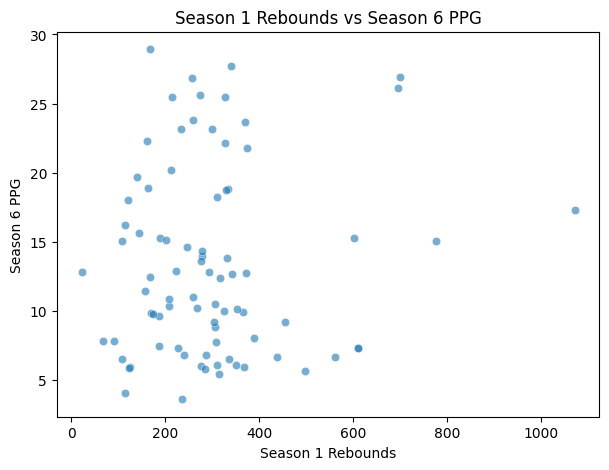

In [ ]:
plt.figure(figsize=(7, 5))
sns.scatterplot(
    x='Season_1_REB',
    y='Season_6_PPG',
    data=second_model,
    alpha=0.6
)

plt.title("Season 1 Rebounds vs Season 6 PPG")
plt.xlabel("Season 1 Rebounds")
plt.ylabel("Season 6 PPG")
plt.show()

To try out different models and see what they may give us, we decided to test squared_epsilon_insensitive. Looking at our Season 1 REB scatterplot, there's a pretty large spread in Season 6 PPG even among players with similar rebound totals, as well as a few outliers that are spread even farther away from the majority of our data. Because of this, we thought maybe a loss function that ignores smaller errors within the epsilon range while penalizing errors outside of it could be interesting to test.

<br>

Squared_epsilon_insensitive didn't perform as well as squared error. Both the training and testing R^2 values decreased. Training went from .3137 to .3048 and testing went from .3191 to .2859. This makes sense due to most of our data having strong correlation with points. So despite variables like rebounds having outliers, squared error seems to perform better than squared_epsilon_insensitive.  



In [ ]:
huber_model = TransformedTargetRegressor(
    regressor=make_pipeline(
        StandardScaler(),
        SGDRegressor(
            loss='huber',
            epsilon=1.35,
            max_iter=1000,
            eta0=0.01,
            random_state=0,
            verbose=1
        )
    ),
    transformer=StandardScaler()
)

In [ ]:
huber_model.fit(X_train, y_train)
# X: Season 1 PPG, Season 1 MIN, Season 1 AST, Season 1 STL, Season 1 TOV, Season 1 height_cm, Season 1 weight, Season 1 GP, Season 1 REB
# y: Season 6 PPG

-- Epoch 1
Norm: 0.15, NNZs: 9, Bias: -0.014743, T: 65, Avg. loss: 0.428106
Total training time: 0.00 seconds.
-- Epoch 2
Norm: 0.20, NNZs: 9, Bias: -0.019570, T: 130, Avg. loss: 0.386602
Total training time: 0.00 seconds.
-- Epoch 3
Norm: 0.24, NNZs: 9, Bias: -0.022886, T: 195, Avg. loss: 0.374490
Total training time: 0.00 seconds.
-- Epoch 4
Norm: 0.26, NNZs: 9, Bias: -0.025743, T: 260, Avg. loss: 0.367491
Total training time: 0.00 seconds.
-- Epoch 5
Norm: 0.28, NNZs: 9, Bias: -0.027654, T: 325, Avg. loss: 0.362264
Total training time: 0.00 seconds.
-- Epoch 6
Norm: 0.30, NNZs: 9, Bias: -0.029126, T: 390, Avg. loss: 0.358815
Total training time: 0.00 seconds.
-- Epoch 7
Norm: 0.31, NNZs: 9, Bias: -0.030878, T: 455, Avg. loss: 0.355414
Total training time: 0.00 seconds.
-- Epoch 8
Norm: 0.32, NNZs: 9, Bias: -0.032561, T: 520, Avg. loss: 0.353086
Total training time: 0.00 seconds.
-- Epoch 9
Norm: 0.33, NNZs: 9, Bias: -0.034381, T: 585, Avg. loss: 0.350890
Total training time: 0.00 se

TransformedTargetRegressor(regressor=Pipeline(steps=[('standardscaler',
                                                      StandardScaler()),
                                                     ('sgdregressor',
                                                      SGDRegressor(epsilon=1.35,
                                                                   loss='huber',
                                                                   random_state=0,
                                                                   verbose=1))]),
                           transformer=StandardScaler())

In [ ]:
y_pred_train_huber = huber_model.predict(X_train)
y_pred_test_huber = huber_model.predict(X_test)

r2_train = r2_score(y_train, y_pred_train_huber)
r2_test = r2_score(y_test, y_pred_test_huber)

print(f"Train R²: {r2_train:.4f}")
print(f"Test R²: {r2_test:.4f}")

mae_train = mean_absolute_error(y_train, y_pred_train_huber)
mae_test = mean_absolute_error(y_test, y_pred_test_huber)

print(f"Train MAE: {mae_train:.2f} PPG")
print(f"Test MAE: {mae_test:.2f} PPG")

Train R²: 0.2971
Test R²: 0.3680
Train MAE: 4.17 PPG
Test MAE: 5.73 PPG


After testing the squared epsilon-insensitive model, we wanted to try Huber loss and see how it'd perform with our data. Since Huber treats smaller errors more like squared error while still being less sensitive to larger ones, it'd help us prevent some of those larger errors from heavily affecting our model.

<br>

We wanted to see whether this approach would work better with some of the spread and potential outliers we saw earlier in our data. We can then compare its R² and prediction errors to our previous models to see how differently Huber performs.

In [ ]:
huber_model_2 = TransformedTargetRegressor(
    regressor=make_pipeline(
        StandardScaler(),
        SGDRegressor(
            loss='huber',
            epsilon=1.3,
            max_iter=1000,
            eta0=0.012,
            random_state=0,
            verbose=1
        )
    ),
    transformer=StandardScaler()
)

huber_model_2.fit(X_train, y_train)
# X: Season 1 PPG, Season 1 MIN, Season 1 AST, Season 1 STL, Season 1 TOV, Season 1 height_cm, Season 1 weight, Season 1 GP, Season 1 REB
# y: Season 6 PPG

-- Epoch 1
Norm: 0.17, NNZs: 9, Bias: -0.018896, T: 65, Avg. loss: 0.422170
Total training time: 0.00 seconds.
-- Epoch 2
Norm: 0.22, NNZs: 9, Bias: -0.024843, T: 130, Avg. loss: 0.381326
Total training time: 0.00 seconds.
-- Epoch 3
Norm: 0.25, NNZs: 9, Bias: -0.028665, T: 195, Avg. loss: 0.369716
Total training time: 0.00 seconds.
-- Epoch 4
Norm: 0.28, NNZs: 9, Bias: -0.031978, T: 260, Avg. loss: 0.362632
Total training time: 0.00 seconds.
-- Epoch 5
Norm: 0.31, NNZs: 9, Bias: -0.033661, T: 325, Avg. loss: 0.357239
Total training time: 0.00 seconds.
-- Epoch 6
Norm: 0.32, NNZs: 9, Bias: -0.034988, T: 390, Avg. loss: 0.353780
Total training time: 0.00 seconds.
-- Epoch 7
Norm: 0.33, NNZs: 9, Bias: -0.036765, T: 455, Avg. loss: 0.350148
Total training time: 0.00 seconds.
-- Epoch 8
Norm: 0.35, NNZs: 9, Bias: -0.038586, T: 520, Avg. loss: 0.347922
Total training time: 0.00 seconds.
-- Epoch 9
Norm: 0.36, NNZs: 9, Bias: -0.040591, T: 585, Avg. loss: 0.345773
Total training time: 0.00 se

TransformedTargetRegressor(regressor=Pipeline(steps=[('standardscaler',
                                                      StandardScaler()),
                                                     ('sgdregressor',
                                                      SGDRegressor(epsilon=1.3,
                                                                   eta0=0.012,
                                                                   loss='huber',
                                                                   random_state=0,
                                                                   verbose=1))]),
                           transformer=StandardScaler())

In [ ]:
y_pred_train_huber_2 = huber_model_2.predict(X_train)
y_pred_test_huber_2 = huber_model_2.predict(X_test)

r2_train = r2_score(y_train, y_pred_train_huber_2)
r2_test = r2_score(y_test, y_pred_test_huber_2)

print(f"Train R²: {r2_train:.4f}")
print(f"Test R²: {r2_test:.4f}")

mae_train = mean_absolute_error(y_train, y_pred_train_huber_2)
mae_test = mean_absolute_error(y_test, y_pred_test_huber_2)

print(f"Train MAE: {mae_train:.2f} PPG")
print(f"Test MAE: {mae_test:.2f} PPG")

Train R²: 0.3013
Test R²: 0.3603
Train MAE: 4.14 PPG
Test MAE: 5.71 PPG


I didn't want to show every single time I changed the epsilon or eta because it'll make the whole thing messy but, after changing the epsilon to larger numbers like 1.5 and 2.0, it didn't do too much. Changing the eta had a much larger effect on the model as we increased it, but it was also very sensitive to these changes.

<br>

If we were to continue using Huber, we'd have to fine tune it a lot more to find a balance where we can improve our testing R² of 0.3603, while also lowering our testing MAE of 5.71 PPG without hurting the model's overall performance. It'd just take too long so, based on what we've tested so far, the amount of fine tuning Huber needs may not be worth the small improvements we're getting from it.

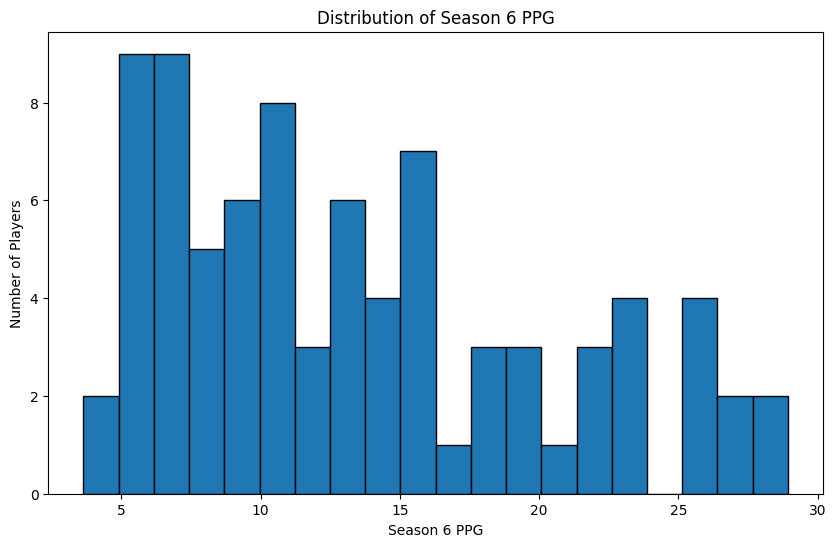

In [ ]:
plt.figure(figsize=(10, 6))

plt.hist(second_model['Season_6_PPG'], bins=20, edgecolor='black')

plt.xlabel('Season 6 PPG')
plt.ylabel('Number of Players')
plt.title('Distribution of Season 6 PPG')

plt.show()

Looking at the distribution of Season 6 PPG, we can see that most players are concentrated toward the lower and middle PPG values, while fewer players reach the higher end of the distribution. We're bringing this distribution up because we now want to determine what PPG value could reasonably separate a normal everyday professinal NBA player from what we would consider a Franchise Level player. Instead of choosing that cutoff randomly, we're going to look at different percentiles of Season 6 PPG.

In [ ]:
second_model['Season_6_PPG'].quantile([0.75, 0.80, 0.85, 0.90])

,Season_6_PPG
0.75,18.219930
0.80,19.561538
0.85,22.306215
0.90,23.805473


We're creating a histogram and looking at different percentiles to help us define what a Franchise Level player's PPG would be. For our project, we're considering a Franchise Level player as someone who develops into one of the higher-level scorers in the NBA by their 6th season. We chose this 6th season because we see the first few seasons of a player's career as their developmental years, where they're still young and adjusting to the NBA. By another three seasons, we believe they should have a much better idea of who they are as a player and what their role in the NBA is.

<br>

We also didn't want to choose a random PPG number as our Franchise Level threshold because that could add some bias to our project. Looking at the percentiles, we can see a larger jump from the 80th percentile at around 19.56 PPG to the 85th percentile at around 22.31 PPG. Because of this, we decided to use the 85th percentile as our threshold for a Franchise Level scorer.

<br>

This connects back to our research question because we can now test whether a player's statistics from earlier in their career can help us predict whether they'll reach this level by their 6th.

In [ ]:
franchise_cutoff = second_model['Season_6_PPG'].quantile(0.85)

second_model['Franchise_Player'] = (
    second_model['Season_6_PPG'] >= franchise_cutoff
).astype(int)

print("Franchise Player PPG Cutoff:", franchise_cutoff)

second_model['Franchise_Player'].value_counts()

Franchise Player PPG Cutoff: 22.306214689265534


,count
Franchise_Player,
0,69
1,13


In [ ]:
franchise_cutoff = second_model['Season_6_PPG'].quantile(0.85)

predicted_franchise = (new_y_pred_test >= franchise_cutoff).astype(int)
actual_franchise = (y_test >= franchise_cutoff).astype(int)

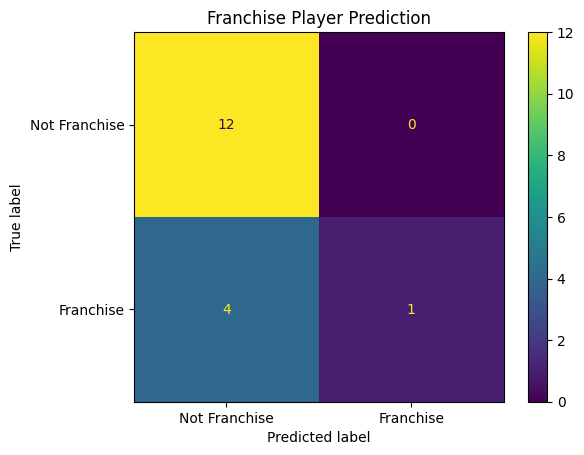

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(actual_franchise, predicted_franchise)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Not Franchise', 'Franchise']
)

disp.plot()
plt.title('Franchise Player Prediction')
plt.show()

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("Accuracy:", accuracy_score(actual_franchise, predicted_franchise))
print("Precision:", precision_score(actual_franchise, predicted_franchise, zero_division=0))
print("Recall:", recall_score(actual_franchise, predicted_franchise, zero_division=0))
print("F1 Score:", f1_score(actual_franchise, predicted_franchise, zero_division=0))

Accuracy: 0.7647058823529411
Precision: 1.0
Recall: 0.2
F1 Score: 0.3333333333333333


From what we can see, the base model so far has an Accuracy of around 76% and a Precision of 1.00. The issue is with the Recall being 0.20 and F1 being 0.33. Out of the 5 actual Franchise Players, the model only identified 1 of them. This is good for us to know because at least now we know what direction our model still needs to go in, which is actually trying to identify the Franchise Players.

One of the main problems with our current model is that we have too many variables included. To start, we're going to remove both height and weight from our model. Every other stat we're using has a positive linear relationship with PPG while height's correlation was -0.08 and weight's was -0.02. These stats are both likely causing noise. Since Squared_Error has the most stable loss function, with a training R² of 0.3137 and testing R² of 0.3191, we're going to use it going forward, despite some concerns with outliers.

In [ ]:
X2 = second_model[['Season_1_PPG','Season_1_MIN', 'Season_1_AST', 'Season_1_STL', 'Season_1_TOV','Season_1_GP', 'Season_1_REB']]
y2 = second_model["Season_6_PPG"]

In [ ]:
X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y2, test_size=0.20, random_state=42
)

In [ ]:
vars_linreg_gd_model = make_pipeline(
    StandardScaler(),
    SGDRegressor(
        loss='squared_error',
        max_iter=1000,
        eta0=0.01,
        learning_rate='constant',
        random_state=42,
        verbose=0
    )
)

In [ ]:
vars_linreg_gd_model.fit(X2_train, y2_train)


Pipeline(steps=[('standardscaler', StandardScaler()),
                ('sgdregressor',
                 SGDRegressor(learning_rate='constant', random_state=42))])

In [ ]:
vars_y_pred_train = vars_linreg_gd_model.predict(X2_train)
vars_y_pred_test  = vars_linreg_gd_model.predict(X2_test)

# r-squared and adjusted r-squared
vars_r2_train = r2_score(y2_train, vars_y_pred_train)
vars_r2_test  = r2_score(y2_test, vars_y_pred_test)

print(f"Train R²: {vars_r2_train:.4f}")
print(f"Test  R²: {vars_r2_test:.4f}")

# mean absolute error
vars_mae_train = mean_absolute_error(y2_train, vars_y_pred_train)
vars_mae_test = mean_absolute_error(y2_test, vars_y_pred_test)

print(f"Training MSE: {mean_squared_error(y2_train, vars_y_pred_train):.2f}")
print(f"Testing MSE: {mean_squared_error(y2_test, vars_y_pred_test):.2f}")


Train R²: 0.3039
Test  R²: 0.4339
Training MSE: 26.02
Testing MSE: 39.98


By removing height and weight we saw a slight downtick in our training R^2, 0.3137 to 0.3039, and a significant uptick in our test R^2, 0.3191 to 0.4339.



Still, 7 variables in the model seems noisy, so we will test if we can get similar or better results with fewer variables. Next we will try only using Points Rebounds and Assists. These are the three most commonly cited basketball statistics when discussing how good a player is, so we hypothesize they will be good predictors of future success.  

In [ ]:
X3 = second_model[['Season_1_PPG', 'Season_1_AST', 'Season_1_REB']]
y3 = second_model["Season_6_PPG"]

In [ ]:
X3_train, X3_test, y3_train, y3_test = train_test_split(
    X3, y3, test_size=0.20, random_state=42
)

In [ ]:
vars3_linreg_gd_model = make_pipeline(
    StandardScaler(),
    SGDRegressor(
        loss='squared_error',
        max_iter=1000,
        eta0=0.01,
        learning_rate='constant',
        random_state=42,
        verbose=0
    )
)

In [ ]:
vars3_linreg_gd_model.fit(X3_train, y3_train)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('sgdregressor',
                 SGDRegressor(learning_rate='constant', random_state=42))])

In [ ]:
vars3_y_pred_train = vars3_linreg_gd_model.predict(X3_train)
vars3_y_pred_test = vars3_linreg_gd_model.predict(X3_test)

vars3_r2_train = r2_score(y3_train, vars3_y_pred_train)
vars3_r2_test = r2_score(y3_test, vars3_y_pred_test)

print(f"Train R²: {vars3_r2_train:.4f}")
print(f"Test R²: {vars3_r2_test:.4f}")

print(f"Training MSE: {mean_squared_error(y3_train, vars3_y_pred_train):.2f}")
print(f"Testing MSE: {mean_squared_error(y3_test, vars3_y_pred_test):.2f}")

Train R²: 0.2621
Test R²: 0.4805
Training MSE: 27.59
Testing MSE: 36.69


This change surprisingly didn't help our model as much as we expected. Our training R² dropped to 0.2621 while our testing R² increased to 0.4805. Despite this having our highest testing R² so far, since it's a smaller dataset, this improvement could be due to sampling variance rather than an actual improvement to the model.

We decided for our next attempt to remove rebounds and focus more on turnovers and steals. As we saw earlier in the data Rebounds had more outliers, making it a shaky predictor. Both steals and turnovers relate with having the ball in your hand, to turn it over you need to at first have it, and if you steal it you now have the ball.

In [ ]:
X4 = second_model[['Season_1_PPG', 'Season_1_AST', 'Season_1_STL', 'Season_1_TOV']]
y4 = second_model["Season_6_PPG"]

X4_train, X4_test, y4_train, y4_test = train_test_split(
    X4, y4, test_size=0.20, random_state=42
)

vars4_linreg_gd_model = make_pipeline(
    StandardScaler(),
    SGDRegressor(
        loss='squared_error',
        max_iter=1000,
        eta0=0.01,
        learning_rate='constant',
        random_state=42,
        verbose=0
    )
)

vars4_linreg_gd_model.fit(X4_train, y4_train)

vars4_y_pred_train = vars4_linreg_gd_model.predict(X4_train)
vars4_y_pred_test = vars4_linreg_gd_model.predict(X4_test)

vars4_r2_train = r2_score(y4_train, vars4_y_pred_train)
vars4_r2_test = r2_score(y4_test, vars4_y_pred_test)

print(f"Train R²: {vars4_r2_train:.4f}")
print(f"Test R²: {vars4_r2_test:.4f}")

print(f"Training MSE: {mean_squared_error(y4_train, vars4_y_pred_train):.2f}")
print(f"Testing MSE: {mean_squared_error(y4_test, vars4_y_pred_test):.2f}")

Train R²: 0.2742
Test R²: 0.4537
Training MSE: 27.13
Testing MSE: 38.59


We saw a similar outcome here as the model above, with a training R² of 0.2742 and a testing R² of 0.4537. There seems to be no clear improvement to our model with this version of variables. Surprisingly, we saw more success with more variables than less. Since 7 variables is where we have had the most success, we're going to plug all of them back in besides steals. Steals are a pure defensive statistic, so they may be leading to noise when predicting future offensive production.

In [ ]:
X5 = second_model[
    ['Season_1_PPG','Season_1_MIN', 'Season_1_AST', 'Season_1_TOV','Season_1_GP', 'Season_1_REB']
]
y5 = second_model["Season_6_PPG"]

X5_train, X5_test, y5_train, y5_test = train_test_split(
    X5, y5, test_size=0.20, random_state=42
)

vars5_linreg_gd_model = make_pipeline(
    StandardScaler(),
    SGDRegressor(
        loss='squared_error',
        max_iter=1000,
        eta0=0.01,
        learning_rate='constant',
        random_state=42,
        verbose=0
    )
)

vars5_linreg_gd_model.fit(X5_train, y5_train)

vars5_y_pred_train = vars5_linreg_gd_model.predict(X5_train)
vars5_y_pred_test = vars5_linreg_gd_model.predict(X5_test)

vars5_r2_train = r2_score(y5_train, vars5_y_pred_train)
vars5_r2_test = r2_score(y5_test, vars5_y_pred_test)

print(f"Train R²: {vars5_r2_train:.4f}")
print(f"Test R²: {vars5_r2_test:.4f}")

print(f"Training MSE: {mean_squared_error(y5_train, vars5_y_pred_train):.2f}")
print(f"Testing MSE: {mean_squared_error(y5_test, vars5_y_pred_test):.2f}")

Train R²: 0.3000
Test R²: 0.4691
Training MSE: 26.17
Testing MSE: 37.50


Out of all of the different variable combinations we created, we decided that this model was the one we felt like was the strongest. Our training R² was around 0.30 while our testing R² increased to around 0.47. Although there's still a noticeable gap between the train/test, the combination gave us one of our better testing performances while still using variables that we believe make sense for predicting future scoring.

Our testing MSE of 37.50 also shows that there's still a decent amount of prediction error. We don't expect this regression model to perfectly identify Franchise Level players but we now want to see what happens when we take these predicted PPG values and classify players using our 22.31 PPG threshold.

Franchise Player PPG Cutoff: 22.31
Accuracy:  0.7647
Precision: 1.0000
Recall:    0.2000
F1 Score:  0.3333


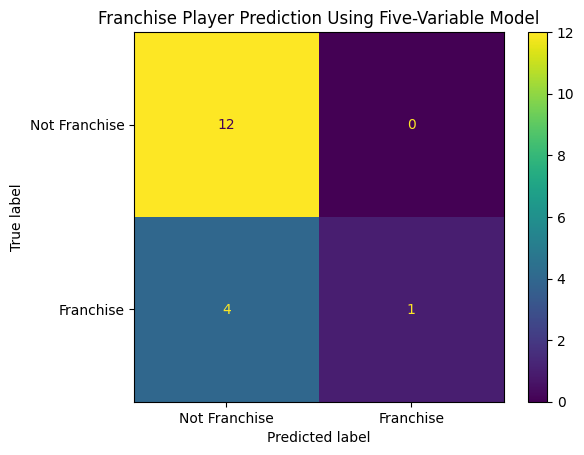

In [ ]:
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import matplotlib.pyplot as plt

franchise_cutoff = second_model['Season_6_PPG'].quantile(0.85)

actual_franchise = (y5_test >= franchise_cutoff).astype(int)
predicted_franchise = (vars5_y_pred_test >= franchise_cutoff).astype(int)

accuracy = accuracy_score(actual_franchise, predicted_franchise)
precision = precision_score(
    actual_franchise, predicted_franchise, zero_division=0
)
recall = recall_score(
    actual_franchise, predicted_franchise, zero_division=0
)
f1 = f1_score(
    actual_franchise, predicted_franchise, zero_division=0
)

print(f"Franchise Player PPG Cutoff: {franchise_cutoff:.2f}")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")

cm = confusion_matrix(actual_franchise, predicted_franchise)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Not Franchise', 'Franchise']
)

disp.plot()
plt.title('Franchise Player Prediction Using Five-Variable Model')
plt.show()

Looking at our classification results, we got an accuracy of around 76%, but our recall was only 0.20. This means that even though our model was getting a decent amount of predictions correct overall, it was only identifying 20% of the actual Franchise Players.

Since our main goal is to identify players who may develop into Franchise Level players, missing this many of them is a pretty big problem. Because of this, we wanted to try a model that directly focuses on classification instead of predicting PPG first and then converting it into a 0 or 1.

# Second Model


Since our goal is now to predict whether a player will become a Franchise Player or not, we're going to test a Support Vector Machine (SVM) as our classification model. For our first attempt, we're using LinearSVC because a lot of the variables we looked at earlier showed some linear relationship with PPG. We're also keeping the same set of variables from our linear regression model that gave us our strongest results.

Instead of predicting a player's exact Season 6 PPG and then converting it into a 0 or 1, LinearSVC will directly classify whether the player reaches our Franchise Player threshold. We want to see if directly treating this as a classification problem can do a better job at identifying those players.

In [ ]:
logistic_test = prediction_df_expanded[['Season_1_PPG','Season_1_MIN', 'Season_1_AST', 'Season_1_STL', 'Season_1_TOV', "Season_1_height_cm", "Season_1_weight", 'Season_1_GP', 'Season_1_REB', 'Season_6_PPG']].dropna()

logistic_test['Franchise_Player_classification'] = (
    logistic_test['Season_6_PPG'] >= franchise_cutoff
).astype(int)

print("Value counts for new 'Franchise_Player_classification' column:")
print(logistic_test['Franchise_Player_classification'].value_counts())

Value counts for new 'Franchise_Player_classification' column:
Franchise_Player_classification
0    69
1    13
Name: count, dtype: int64


In [ ]:
from sklearn.svm import LinearSVC
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Define X and y for classification
X_classification = logistic_test[['Season_1_PPG', 'Season_1_MIN', 'Season_1_AST', 'Season_1_TOV','Season_1_GP', 'Season_1_REB']]
y_classification = logistic_test['Franchise_Player_classification']

# Split data into training and testing sets
X_train_clf, X_test_clf, y_train_clf, y_test_clf = train_test_split(
    X_classification, y_classification, test_size=0.20, random_state=42
)

In [ ]:
# Create and train the LinearSVC model
linear_svc_model = make_pipeline(StandardScaler(), LinearSVC(random_state=42, dual=False, max_iter=1000))
linear_svc_model.fit(X_train_clf, y_train_clf)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('linearsvc', LinearSVC(dual=False, random_state=42))])

--- Training Set Metrics ---
Accuracy:  0.9231
Precision: 1.0000
Recall:    0.3750
F1 Score:  0.5455

--- Testing Set Metrics ---
Accuracy:  0.8235
Precision: 1.0000
Recall:    0.4000
F1 Score:  0.5714


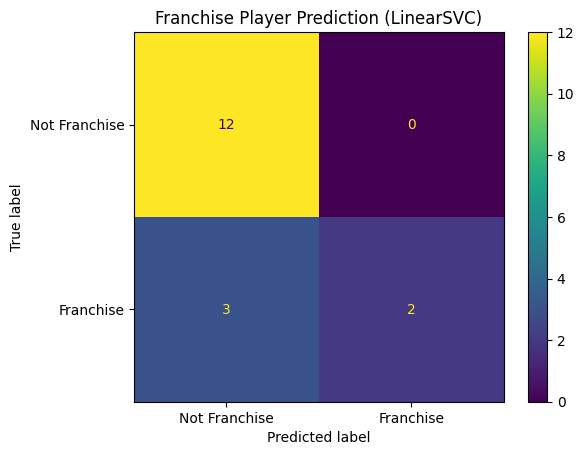

In [ ]:
# Make predictions
y_pred_train_clf = linear_svc_model.predict(X_train_clf)
y_pred_test_clf = linear_svc_model.predict(X_test_clf)

# Evaluate the model
print("--- Training Set Metrics ---")
print(f"Accuracy:  {accuracy_score(y_train_clf, y_pred_train_clf):.4f}")
print(f"Precision: {precision_score(y_train_clf, y_pred_train_clf, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_train_clf, y_pred_train_clf, zero_division=0):.4f}")
print(f"F1 Score:  {f1_score(y_train_clf, y_pred_train_clf, zero_division=0):.4f}")

print("\n--- Testing Set Metrics ---")
print(f"Accuracy:  {accuracy_score(y_test_clf, y_pred_test_clf):.4f}")
print(f"Precision: {precision_score(y_test_clf, y_pred_test_clf, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test_clf, y_pred_test_clf, zero_division=0):.4f}")
print(f"F1 Score:  {f1_score(y_test_clf, y_pred_test_clf, zero_division=0):.4f}")

# Plot Confusion Matrix for Test Set
cm_clf = confusion_matrix(y_test_clf, y_pred_test_clf)
disp_clf = ConfusionMatrixDisplay(
    confusion_matrix=cm_clf,
    display_labels=['Not Franchise', 'Franchise']
)

disp_clf.plot()
plt.title('Franchise Player Prediction (LinearSVC)')
plt.show()

This version performed a little bit better than our linear regression model, especially with its higher Recall and F1 scores. Our testing Recall increased from 0.20 to 0.40 and our F1 increased from 0.33 to 0.57, meaning the model was able to identify more of the actual Franchise Players. Because of that, we decided to continue testing and optimizing the SVM (Support Vector Machine).

<br>

Now that we're using LinearSVC for classification instead of our previous regression model, the default loss function is squared hinge. To see if we could improve the model further, we decided to test regular hinge loss instead. Since our dataset is relatively small, we wanted to see if regular hinge loss would perform better with our data.

--- Training Set Metrics: Hinge Loss ---
Accuracy:  0.9231
Precision: 1.0000
Recall:    0.3750
F1 Score:  0.5455

--- Testing Set Metrics: Hinge Loss ---
Accuracy:  0.8235
Precision: 1.0000
Recall:    0.4000
F1 Score:  0.5714


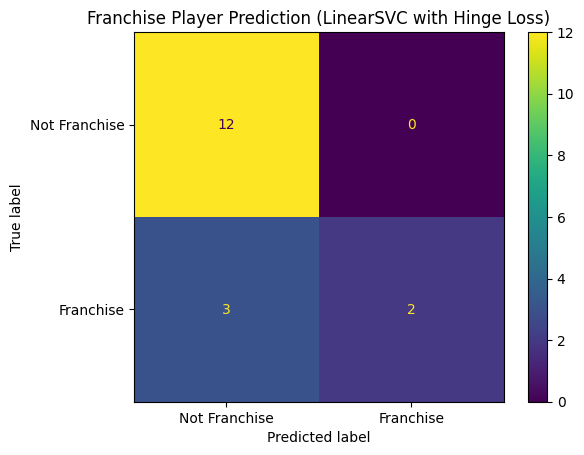

In [ ]:
from sklearn.svm import LinearSVC
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Define X and y for classification
X_classification_hinge = logistic_test[
    [
        'Season_1_PPG',
        'Season_1_MIN',
        'Season_1_AST',
        'Season_1_TOV',
        'Season_1_GP',
        'Season_1_REB'
    ]
]

y_classification_hinge = logistic_test[
    'Franchise_Player_classification'
]

# Split data into training and testing sets
X_train_hinge, X_test_hinge, y_train_hinge, y_test_hinge = train_test_split(
    X_classification_hinge,
    y_classification_hinge,
    test_size=0.20,
    random_state=42
)

# Create and train the LinearSVC model using hinge loss
linear_svc_hinge_model = make_pipeline(
    StandardScaler(),
    LinearSVC(
        random_state=42,
        loss='hinge',
        dual=True,
        max_iter=1000
    )
)

linear_svc_hinge_model.fit(
    X_train_hinge,
    y_train_hinge
)

# Make predictions
y_pred_train_hinge = linear_svc_hinge_model.predict(X_train_hinge)
y_pred_test_hinge = linear_svc_hinge_model.predict(X_test_hinge)

# Evaluate the model
print("--- Training Set Metrics: Hinge Loss ---")
print(f"Accuracy:  {accuracy_score(y_train_hinge, y_pred_train_hinge):.4f}")
print(f"Precision: {precision_score(y_train_hinge, y_pred_train_hinge, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_train_hinge, y_pred_train_hinge, zero_division=0):.4f}")
print(f"F1 Score:  {f1_score(y_train_hinge, y_pred_train_hinge, zero_division=0):.4f}")

print("\n--- Testing Set Metrics: Hinge Loss ---")
print(f"Accuracy:  {accuracy_score(y_test_hinge, y_pred_test_hinge):.4f}")
print(f"Precision: {precision_score(y_test_hinge, y_pred_test_hinge, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test_hinge, y_pred_test_hinge, zero_division=0):.4f}")
print(f"F1 Score:  {f1_score(y_test_hinge, y_pred_test_hinge, zero_division=0):.4f}")

# Plot confusion matrix for the test set
cm_hinge = confusion_matrix(
    y_test_hinge,
    y_pred_test_hinge
)

disp_hinge = ConfusionMatrixDisplay(
    confusion_matrix=cm_hinge,
    display_labels=['Not Franchise', 'Franchise']
)

disp_hinge.plot()
plt.title('Franchise Player Prediction (LinearSVC with Hinge Loss)')
plt.show()

Changing from squared hinge to regular hinge made no difference in any of our testing statistics. Accuracy stayed at 0.82, Precision stayed at 1.00, Recall stayed at 0.40, and F1 stayed at 0.57. Because of this, we decided to keep looking at what else could be limiting our model.

<br>

One thing we noticed is that our Franchise Player classification is heavily imbalanced, with around 85% of our players being classified as non-Franchise Players. This could cause our model to lean more towards predicting 0 since there are more examples of them in our data. To balance this out, we're going to implement SMOTE to oversample the Franchise Player class in our training data.

<br>

What SMOTE is/does is that it creates new synthetic observations based on similar Franchise Players already in our training data, rather than just duplicating the same observations. This gives our model more examples of Franchise Players to learn from without changing our actual testing data, allowing us to still evaluate the model on real player observations.

--- Training Set Metrics ---
Accuracy:  0.8923
Precision: 0.6000
Recall:    0.9000
F1 Score:  0.7200

--- Testing Set Metrics ---
Accuracy:  0.8824
Precision: 0.6667
Recall:    0.6667
F1 Score:  0.6667


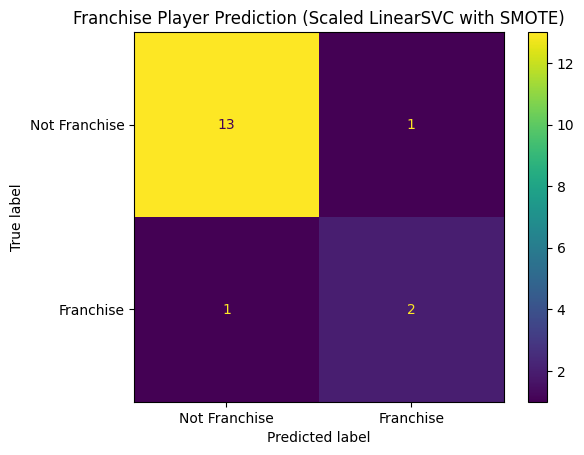

In [ ]:
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Define X and y
X_classification_smote = logistic_test[
    [
        'Season_1_PPG',
        'Season_1_MIN',
        'Season_1_AST',
        'Season_1_TOV',
        'Season_1_GP',
        'Season_1_REB'
    ]
]

y_classification_smote = logistic_test[
    'Franchise_Player_classification'
]

# Split data
X_train_smote, X_test_smote, y_train_smote, y_test_smote = train_test_split(
    X_classification_smote,
    y_classification_smote,
    test_size=0.20,
    random_state=42,
    stratify=y_classification_smote
)

# Pipeline:
# 1. Scale the training data
# 2. Apply SMOTE to the scaled training data
# 3. Fit LinearSVC
smote_svc_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('smote', SMOTE(random_state=42)),
    ('svc', LinearSVC(
        random_state=42,
        dual=True,
        max_iter=1000,
        loss='hinge'
    ))
])

# Train the pipeline
smote_svc_pipeline.fit(X_train_smote, y_train_smote)

# Predict on the original, non-SMOTEd data
y_pred_train_smote = smote_svc_pipeline.predict(X_train_smote)
y_pred_test_smote = smote_svc_pipeline.predict(X_test_smote)

# Evaluate training set
print("--- Training Set Metrics ---")
print(f"Accuracy:  {accuracy_score(y_train_smote, y_pred_train_smote):.4f}")
print(f"Precision: {precision_score(y_train_smote, y_pred_train_smote, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_train_smote, y_pred_train_smote, zero_division=0):.4f}")
print(f"F1 Score:  {f1_score(y_train_smote, y_pred_train_smote, zero_division=0):.4f}")

# Evaluate testing set
print("\n--- Testing Set Metrics ---")
print(f"Accuracy:  {accuracy_score(y_test_smote, y_pred_test_smote):.4f}")
print(f"Precision: {precision_score(y_test_smote, y_pred_test_smote, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test_smote, y_pred_test_smote, zero_division=0):.4f}")
print(f"F1 Score:  {f1_score(y_test_smote, y_pred_test_smote, zero_division=0):.4f}")

# Confusion matrix
cm_smote = confusion_matrix(y_test_smote, y_pred_test_smote)

disp_smote = ConfusionMatrixDisplay(
    confusion_matrix=cm_smote,
    display_labels=['Not Franchise', 'Franchise']
)

disp_smote.plot()
plt.title('Franchise Player Prediction (Scaled LinearSVC with SMOTE)')
plt.show()

In [ ]:
# Show class distribution before and after SMOTE
print("TRAINING DATA BEFORE SMOTE:")
print(y_train_smote.value_counts().sort_index())
print(f"Franchise players before SMOTE: {(y_train_smote == 1).sum()}")

# Create a diagnostic SMOTE object
scaler_for_check = StandardScaler()
X_train_scaled_check = scaler_for_check.fit_transform(X_train_smote)

smote_for_check = SMOTE(random_state=42)
X_train_resampled_check, y_train_resampled_check = (
    smote_for_check.fit_resample(
        X_train_scaled_check,
        y_train_smote
    )
)

print("\nTRAINING DATA AFTER SMOTE:")
print(y_train_resampled_check.value_counts().sort_index())
print(f"Franchise players after SMOTE: {(y_train_resampled_check == 1).sum()}")

print(
    f"\nSMOTE added "
    f"{(y_train_resampled_check == 1).sum() - (y_train_smote == 1).sum()} "
    f"franchise players."
)

TRAINING DATA BEFORE SMOTE:
Franchise_Player_classification
0    55
1    10
Name: count, dtype: int64
Franchise players before SMOTE: 10

TRAINING DATA AFTER SMOTE:
Franchise_Player_classification
0    55
1    55
Name: count, dtype: int64
Franchise players after SMOTE: 55

SMOTE added 45 franchise players.


We can see that before SMOTE our training data had 55 non-Franchise Players compared to only 10 Franchise Players. After applying SMOTE, both classes now have 55 observations in our training data. This gives our model a much more balanced set of data to learn from instead of being heavily influenced by the non-Franchise Player class.

Looking at our results, SMOTE gave us a pretty big improvement. Recall had been one of our biggest problems with the previous models, with our best testing Recall only being 0.40. After using SMOTE, our testing Recall increased to 0.67 and our F1 increased from 0.57 to 0.67. This means our model was able to identify more of the actual Franchise Players after balancing the training data.

One tradeoff we noticed was that our testing Precision dropped from 1.00 to 0.67 because the model became more willing to classify someone as a Franchise Player. We think this tradeoff may be worth it for our research question though, since we're more interested in finding possible Franchise Players and don't want our model to consistently miss them.

Now that SMOTE helped us improve our LinearSVC model, we wanted to see if using a different kernel could improve it even more. So far we've only been using a linear boundary to classify our players, but the relationship between our variables and becoming a Franchise Player may not be completely linear as seen in some of the variables from before. Because of this, we're going to test an RBF (radial) kernel to see if allowing a more flexible decision boundary works better with our data.

Original training target distribution:
Franchise_Player_classification
0    57
1     8
Name: count, dtype: int64

Resampled training target distribution:
Franchise_Player_classification
0    57
1    57
Name: count, dtype: int64
--- Training Set Metrics: Radial SVC with SMOTE ---
Accuracy:  0.9385
Precision: 0.7000
Recall:    0.8750
F1 Score:  0.7778

--- Testing Set Metrics: Radial SVC with SMOTE ---
Accuracy:  0.8235
Precision: 1.0000
Recall:    0.4000
F1 Score:  0.5714


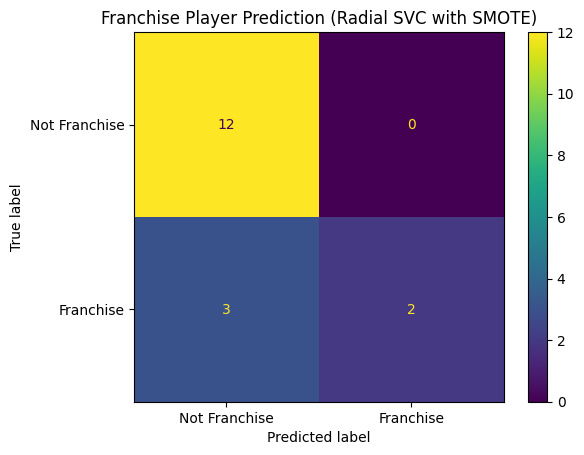

In [ ]:
from sklearn.svm import SVC
from imblearn.over_sampling import SMOTE

# Define X and y for classification
X_classification_radial = logistic_test[
    [
        'Season_1_PPG',
        'Season_1_MIN',
        'Season_1_AST',
        'Season_1_TOV',
        'Season_1_GP',
        'Season_1_REB'
    ]
]

y_classification_radial = logistic_test[
    'Franchise_Player_classification'
]

# Split data into training and testing sets
X_train_radial, X_test_radial, y_train_radial, y_test_radial = train_test_split(
    X_classification_radial,
    y_classification_radial,
    test_size=0.20,
    random_state=42
)

# Apply SMOTE only to the training data
smote_radial = SMOTE(random_state=42)

X_train_resampled_radial, y_train_resampled_radial = (
    smote_radial.fit_resample(
        X_train_radial,
        y_train_radial
    )
)

print("Original training target distribution:")
print(y_train_radial.value_counts())

print("\nResampled training target distribution:")
print(y_train_resampled_radial.value_counts())

# Create and train the radial-kernel SVC model
radial_svc_model_smote = make_pipeline(
    StandardScaler(),
    SVC(
        kernel='rbf',
        C=1.0,
        gamma='scale',
        random_state=42
    )
)

radial_svc_model_smote.fit(
    X_train_resampled_radial,
    y_train_resampled_radial
)

# Make predictions on the original, non-SMOTE training and testing sets
y_pred_train_radial = radial_svc_model_smote.predict(X_train_radial)
y_pred_test_radial = radial_svc_model_smote.predict(X_test_radial)

# Evaluate the model
print("--- Training Set Metrics: Radial SVC with SMOTE ---")
print(f"Accuracy:  {accuracy_score(y_train_radial, y_pred_train_radial):.4f}")
print(f"Precision: {precision_score(y_train_radial, y_pred_train_radial, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_train_radial, y_pred_train_radial, zero_division=0):.4f}")
print(f"F1 Score:  {f1_score(y_train_radial, y_pred_train_radial, zero_division=0):.4f}")

print("\n--- Testing Set Metrics: Radial SVC with SMOTE ---")
print(f"Accuracy:  {accuracy_score(y_test_radial, y_pred_test_radial):.4f}")
print(f"Precision: {precision_score(y_test_radial, y_pred_test_radial, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test_radial, y_pred_test_radial, zero_division=0):.4f}")
print(f"F1 Score:  {f1_score(y_test_radial, y_pred_test_radial, zero_division=0):.4f}")

# Plot confusion matrix for the test set
cm_radial = confusion_matrix(
    y_test_radial,
    y_pred_test_radial
)

disp_radial = ConfusionMatrixDisplay(
    confusion_matrix=cm_radial,
    display_labels=['Not Franchise', 'Franchise']
)

disp_radial.plot()
plt.title('Franchise Player Prediction (Radial SVC with SMOTE)')
plt.show()

Looking at our RBF model, we saw that compared to our LinearSVC with SMOTE, it did worse on the testing data. Our testing Recall dropped from 0.67 to 0.40 and our F1 dropped from 0.67 to 0.57. The RBF kernel also increases the complexity of our model by allowing a nonlinear decision boundary, which doesn't seem necessary if it isn't improving our results too. This also makes sense since a lot of the variables we found most important earlier showed stronger linear relationships.

<br>

Before moving away from RBF completely, we wanted to test different gamma values. Since Gamma controls how much influence individual observations have on the decision boundary, adjusting it may help us find a better fit before deciding whether adding that complexity is worth it.


Gamma: 0.001
Accuracy:  0.9412
Precision: 0.8333
Recall:    1.0000
F1 Score:  0.9091
Confusion Matrix:
[[11  1]
 [ 0  5]]


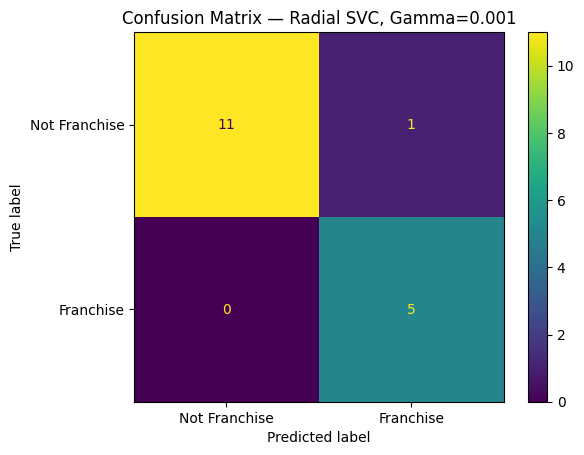


Gamma: 0.01
Accuracy:  1.0000
Precision: 1.0000
Recall:    1.0000
F1 Score:  1.0000
Confusion Matrix:
[[12  0]
 [ 0  5]]


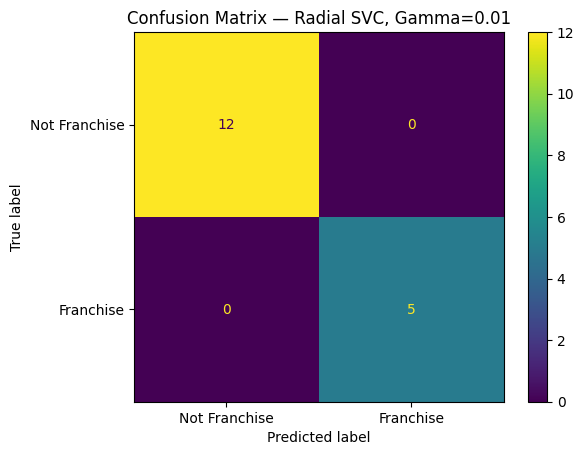


Gamma: 0.1
Accuracy:  0.8235
Precision: 1.0000
Recall:    0.4000
F1 Score:  0.5714
Confusion Matrix:
[[12  0]
 [ 3  2]]


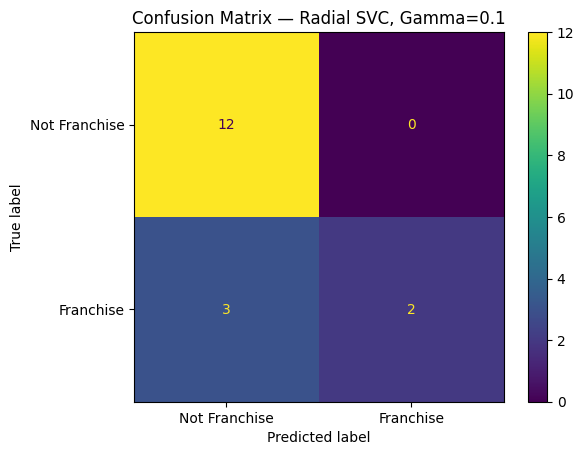


Gamma: 1
Accuracy:  0.7059
Precision: 0.0000
Recall:    0.0000
F1 Score:  0.0000
Confusion Matrix:
[[12  0]
 [ 5  0]]


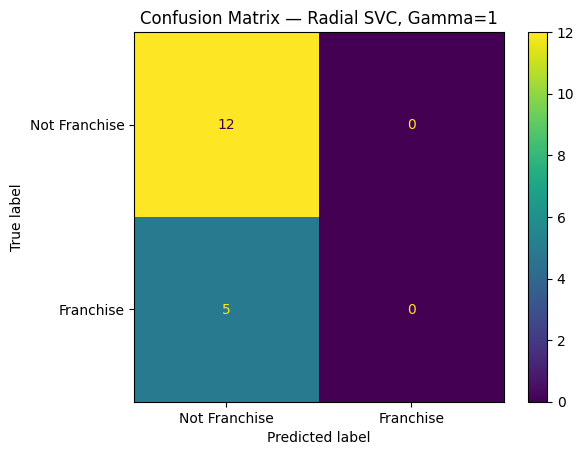


Gamma: 10
Accuracy:  0.7059
Precision: 0.0000
Recall:    0.0000
F1 Score:  0.0000
Confusion Matrix:
[[12  0]
 [ 5  0]]


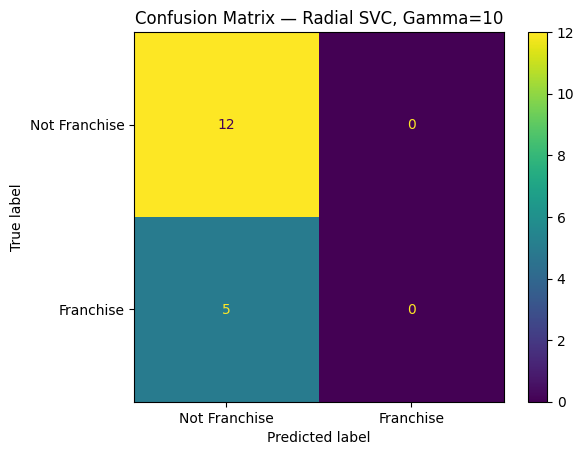

In [ ]:
from sklearn.svm import SVC

gamma_values = [0.001, 0.01, 0.1, 1, 10]

for gamma_value in gamma_values:
    radial_svc_gamma_model = make_pipeline(
        StandardScaler(),
        SVC(
            kernel='rbf',
            C=1.0,
            gamma=gamma_value
        )
    )

    radial_svc_gamma_model.fit(
        X_train_resampled_radial,
        y_train_resampled_radial
    )

    gamma_predictions = radial_svc_gamma_model.predict(X_test_radial)

    gamma_accuracy = accuracy_score(y_test_radial, gamma_predictions)
    gamma_precision = precision_score(
        y_test_radial, gamma_predictions, zero_division=0
    )
    gamma_recall = recall_score(
        y_test_radial, gamma_predictions, zero_division=0
    )
    gamma_f1 = f1_score(
        y_test_radial, gamma_predictions, zero_division=0
    )

    cm_gamma = confusion_matrix(
        y_test_radial,
        gamma_predictions
    )

    print(f"\nGamma: {gamma_value}")
    print(f"Accuracy:  {gamma_accuracy:.4f}")
    print(f"Precision: {gamma_precision:.4f}")
    print(f"Recall:    {gamma_recall:.4f}")
    print(f"F1 Score:  {gamma_f1:.4f}")
    print("Confusion Matrix:")
    print(cm_gamma)

    disp_gamma = ConfusionMatrixDisplay(
        confusion_matrix=cm_gamma,
        display_labels=['Not Franchise', 'Franchise']
    )

    disp_gamma.plot()
    plt.title(f'Confusion Matrix — Radial SVC, Gamma={gamma_value}')
    plt.show()

Looking at the different gamma values, gamma = 0.01 gave us by far the best results, with our Accuracy, Precision, Recall, and F1 all reaching 1.00 on this testing split. Compared to our first RBF model, this is a massive improvement and shows how much of an effect gamma can have on the RBF decision boundary.

The only issue is that getting perfect results is also very suspicious, especially with how small our dataset and testing set are. Before deciding that this is actually our best model, we wanted to test it across different splits of our data to see if these results are consistent, if we just happened to get a really good testing split, or if we overfitted our model.

In [ ]:
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)
import numpy as np

# Radial SVC with gamma fixed at 0.01
radial_svc_kfold_model = Pipeline([
    ('scaler', StandardScaler()),
    ('smote', SMOTE(random_state=42)),
    ('svc', SVC(
        kernel='rbf',
        C=1.0,
        gamma=0.01
    ))
])

# Five-fold cross-validation
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

fold_f1_scores = []

for fold_number, (train_index, validation_index) in enumerate(
    skf.split(X_train_radial, y_train_radial),
    start=1
):
    X_fold_train = X_train_radial.iloc[train_index]
    X_fold_validation = X_train_radial.iloc[validation_index]

    y_fold_train = y_train_radial.iloc[train_index]
    y_fold_validation = y_train_radial.iloc[validation_index]

    radial_svc_kfold_model.fit(
        X_fold_train,
        y_fold_train
    )

    fold_predictions = radial_svc_kfold_model.predict(
        X_fold_validation
    )

    fold_accuracy = accuracy_score(
        y_fold_validation,
        fold_predictions
    )
    fold_precision = precision_score(
        y_fold_validation,
        fold_predictions,
        zero_division=0
    )
    fold_recall = recall_score(
        y_fold_validation,
        fold_predictions,
        zero_division=0
    )
    fold_f1 = f1_score(
        y_fold_validation,
        fold_predictions,
        zero_division=0
    )

    fold_f1_scores.append(fold_f1)

    print(f"\n--- Fold {fold_number} ---")
    print(f"Accuracy:  {fold_accuracy:.4f}")
    print(f"Precision: {fold_precision:.4f}")
    print(f"Recall:    {fold_recall:.4f}")
    print(f"F1 Score:  {fold_f1:.4f}")

print("\n--- Average Five-Fold Results ---")
print(f"Average F1 Score: {np.mean(fold_f1_scores):.4f}")
print(f"F1 Score Std. Dev.: {np.std(fold_f1_scores):.4f}")


--- Fold 1 ---
Accuracy:  0.9231
Precision: 0.0000
Recall:    0.0000
F1 Score:  0.0000

--- Fold 2 ---
Accuracy:  0.7692
Precision: 0.2500
Recall:    1.0000
F1 Score:  0.4000

--- Fold 3 ---
Accuracy:  0.7692
Precision: 0.4000
Recall:    1.0000
F1 Score:  0.5714

--- Fold 4 ---
Accuracy:  0.5385
Precision: 0.0000
Recall:    0.0000
F1 Score:  0.0000

--- Fold 5 ---
Accuracy:  0.8462
Precision: 0.5000
Recall:    0.5000
F1 Score:  0.5000

--- Average Five-Fold Results ---
Average F1 Score: 0.2943
F1 Score Std. Dev.: 0.2464


To make sure our earlier results weren't just coming from a lucky train-test split, we decided to use 5-fold cross-validation. Since our dataset is relatively small, using 5 folds lets us test the model across multiple different splits while still keeping enough observations in each fold to train and validate the model.

<br>

Looking at our 5-fold results, the RBF model wasn't nearly as strong as it actually appeared. Our average F1 dropped to around 0.29 with a standard deviation of around 0.25, meaning that the model's performance changed a lot depending on the data it was trained and tested on. This shows us that our perfect results from earlier weren't consistent and may have been caused by our original train-test split or the model overfitting to our data.

Since our RBF model didn't hold up during 5-fold testing, we wanted to go back and test our LinearSVC SMOTE the same way. This model gave us some of our strongest results earlier, so testing it across multiple folds will help us see if those results are actually more consistent than what we saw with RBF.

In [ ]:
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)
import numpy as np

# Define X and y
X_classification_kfold = logistic_test[
    [
        'Season_1_PPG',
        'Season_1_MIN',
        'Season_1_AST',
        'Season_1_TOV',
        'Season_1_GP',
        'Season_1_REB'
    ]
]

y_classification_kfold = logistic_test[
    'Franchise_Player_classification'
]

# Create training and final testing sets
X_train_kfold, X_test_kfold, y_train_kfold, y_test_kfold = train_test_split(
    X_classification_kfold,
    y_classification_kfold,
    test_size=0.20,
    random_state=42,
    stratify=y_classification_kfold
)

# LinearSVC model with SMOTE inside the pipeline
linear_svc_kfold_smote = Pipeline([
    ('scaler', StandardScaler()),
    ('smote', SMOTE(random_state=42)),
    ('linear_svc', LinearSVC(
        random_state=42,
        dual=True,
        loss='hinge',
        max_iter=1000
    ))
])

# Five-fold stratified cross-validation
stratified_kfold = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

kfold_accuracy_scores = []
kfold_f1_scores = []

for fold_number, (train_index, validation_index) in enumerate(
    stratified_kfold.split(X_train_kfold, y_train_kfold),
    start=1
):
    X_fold_train = X_train_kfold.iloc[train_index]
    X_fold_validation = X_train_kfold.iloc[validation_index]

    y_fold_train = y_train_kfold.iloc[train_index]
    y_fold_validation = y_train_kfold.iloc[validation_index]

    linear_svc_kfold_smote.fit(
        X_fold_train,
        y_fold_train
    )

    fold_predictions = linear_svc_kfold_smote.predict(
        X_fold_validation
    )

    fold_accuracy = accuracy_score(
        y_fold_validation,
        fold_predictions
    )
    fold_precision = precision_score(
        y_fold_validation,
        fold_predictions,
        zero_division=0
    )
    fold_recall = recall_score(
        y_fold_validation,
        fold_predictions,
        zero_division=0
    )
    fold_f1 = f1_score(
        y_fold_validation,
        fold_predictions,
        zero_division=0
    )

    fold_confusion_matrix = confusion_matrix(
        y_fold_validation,
        fold_predictions,
        labels=[0, 1]
    )

    # Store the correct metric in each list
    kfold_accuracy_scores.append(fold_accuracy)
    kfold_f1_scores.append(fold_f1)

    print(f"\n--- Fold {fold_number} ---")
    print(f"Accuracy:  {fold_accuracy:.4f}")
    print(f"Precision: {fold_precision:.4f}")
    print(f"Recall:    {fold_recall:.4f}")
    print(f"F1 Score:  {fold_f1:.4f}")
    print("Confusion Matrix:")
    print(fold_confusion_matrix)

# Average cross-validation results
print("\n--- Average Five-Fold Results ---")
print(f"Average Accuracy: {np.mean(kfold_accuracy_scores):.4f}")
print(f"Average F1 Score: {np.mean(kfold_f1_scores):.4f}")
print(f"F1 Score Std. Dev.: {np.std(kfold_f1_scores):.4f}")

# Train final model on all training data
linear_svc_kfold_smote.fit(
    X_train_kfold,
    y_train_kfold
)

# Evaluate final model on untouched test data
final_test_predictions = linear_svc_kfold_smote.predict(
    X_test_kfold
)

print("\n--- Final Test Set Results ---")
print(f"Accuracy:  {accuracy_score(y_test_kfold, final_test_predictions):.4f}")
print(f"Precision: {precision_score(y_test_kfold, final_test_predictions, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test_kfold, final_test_predictions, zero_division=0):.4f}")
print(f"F1 Score:  {f1_score(y_test_kfold, final_test_predictions, zero_division=0):.4f}")

print("Final Test Confusion Matrix:")
print(confusion_matrix(
    y_test_kfold,
    final_test_predictions,
    labels=[0, 1]
))


--- Fold 1 ---
Accuracy:  0.8462
Precision: 0.5000
Recall:    0.5000
F1 Score:  0.5000
Confusion Matrix:
[[10  1]
 [ 1  1]]

--- Fold 2 ---
Accuracy:  0.8462
Precision: 0.5000
Recall:    1.0000
F1 Score:  0.6667
Confusion Matrix:
[[9 2]
 [0 2]]

--- Fold 3 ---
Accuracy:  0.6923
Precision: 0.2500
Recall:    0.5000
F1 Score:  0.3333
Confusion Matrix:
[[8 3]
 [1 1]]

--- Fold 4 ---
Accuracy:  0.8462
Precision: 0.5000
Recall:    1.0000
F1 Score:  0.6667
Confusion Matrix:
[[9 2]
 [0 2]]

--- Fold 5 ---
Accuracy:  0.9231
Precision: 0.6667
Recall:    1.0000
F1 Score:  0.8000
Confusion Matrix:
[[10  1]
 [ 0  2]]

--- Average Five-Fold Results ---
Average Accuracy: 0.8308
Average F1 Score: 0.5933
F1 Score Std. Dev.: 0.1611

--- Final Test Set Results ---
Accuracy:  0.8824
Precision: 0.6667
Recall:    0.6667
F1 Score:  0.6667
Final Test Confusion Matrix:
[[13  1]
 [ 1  2]]


/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


Looking at our 5-fold results, LinearSVC with SMOTE performed much better than RBF. Our average F1 increased from around 0.29 with RBF to 0.59 with LinearSVC and SMOTE, while the standard deviation dropped from around 0.25 to 0.16. This shows that LinearSVC with SMOTE performed better and was more consistent across the different folds.

**Final Model Choice**

In [ ]:
# Final Model: LinearSVC with SMOTE

final_model = Pipeline([
    ('scaler', StandardScaler()),
    ('smote', SMOTE(random_state=42)),
    ('linear_svc', LinearSVC(
        random_state=42,
        dual=True,
        loss='hinge',
        max_iter=1000
    ))
])

# Train the final model
final_model.fit(X_train_kfold, y_train_kfold)

# Make predictions on the testing data
final_pred = final_model.predict(X_test_kfold)

# Display final model settings
print("FINAL MODEL: LinearSVC + SMOTE")
print("Loss: hinge")
print("Max Iterations: 1000")
print("SMOTE: Yes")

print("\nFINAL TEST RESULTS:")
print(f"Accuracy:  {accuracy_score(y_test_kfold, final_pred):.4f}")
print(f"Precision: {precision_score(y_test_kfold, final_pred, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test_kfold, final_pred, zero_division=0):.4f}")
print(f"F1 Score:  {f1_score(y_test_kfold, final_pred, zero_division=0):.4f}")

FINAL MODEL: LinearSVC + SMOTE
Loss: hinge
Max Iterations: 1000
SMOTE: Yes

FINAL TEST RESULTS:
Accuracy:  0.8824
Precision: 0.6667
Recall:    0.6667
F1 Score:  0.6667


**Conclusion + Final Model Choice**

Our goal with this project was to determine whether a player's rookie season statistics could be used to predict whether they would become a Franchise Player later in their career. Through our regression models, we found that rookie statistics did have some relationship with a player's future scoring, but they weren't enough to fully explain future performance. Our last regression model had a training R² of around 0.30 and a testing R² of around 0.47, meaning that while these variables contained useful information, there was still a large amount of variation that our regression models couldn't explain. Since our main goal was to identify Franchise Players rather than predict their exact Season 6 PPG, we decided to move away from regression and use classification for our final model.

<br>

When choosing our variables, we used both the results from our models and our own basketball knowledge to decide which statistics could be meaningful. One of the more interesting findings was that our models performed much better when we used around 6-7 variables compared to when we reduced the model to only 2-3 variables. Initially, we thought that using only Points, Rebounds, and Assists would give us better results because these 3 are one of the most commonly used statistics when discussing a player's performance, and we thought they would have a stronger relationship with future scoring. However, our results showed that our original thought process wasn't entirely correct. Focusing on only a few parts of a player's game left out useful information. We believe this may be because a player's potential can't be represented well by only one or two parts of their game. Points, minutes, games played, assists, rebounds, and turnovers together can give the model a broader picture of both a rookie's production and how involved they are when given opportunities to play. Instead of only looking at what we thought would directly contribute to scoring, we needed to understand more of the player's overall game. This eventually led to our final predictors of Season 1 PPG, MIN, AST, TOV, GP, and REB.

<br>

Because of this, we now hypothesize that looking at more parts of a rookie's game may also tell us something about how the team views that player. If a rookie is already producing around the level of an average NBA player across different parts of the game, it could be a sign that they're adapting quickly and that their team sees enough potential to continue investing playing time and opportunities into them. It's similar to a new employee entering a job and already performing around the level of more experienced workers without having the same amount of experience. The team giving a rookie these opportunities could allow them to continue developing and eventually produce stats at a higher level later in their career. We originally tested variables such as height, weight, and steals as well, but found that not every additional variable was helpful. This showed us that it wasn't necessarily about having more variables, but having multiple useful variables that gave us a better picture of the player's overall game.

<br>

For our final model, we decided to use LinearSVC with hinge loss and SMOTE. SMOTE helped account for the imbalance between Franchise Players and non-Franchise Players, which had caused our earlier models to struggle with Recall. Our final model had a testing Accuracy of around 0.88, with Precision, Recall, and F1 scores of around 0.67. Compared to our earlier classification models, this gave us a better balance between identifying Franchise Players and keeping our overall predictions accurate.

<br>

Testing multiple modeling strategies also taught us why it was important not to choose a model based on a single train-test split. Our RBF model initially reached an Accuracy, Precision, Recall, and F1 of 1.00 with gamma = 0.01, but those results didn't hold up during cross-validation. LinearSVC with SMOTE had an average cross-validation F1 of around 0.59 with a standard deviation of around 0.16, compared to an average F1 of around 0.29 and standard deviation of around 0.25 for RBF. This showed us that LinearSVC with SMOTE gave us stronger and more consistent results across our data.

<br>

Our final model could provide a good foothold for identifying rookie players who may have the potential to develop into Franchise Players. With a testing Accuracy of around 0.88 and Recall and F1 scores of around 0.67, the model isn't perfect, but it could definitely help narrow down which rookies may be worth looking into further. The 12% of error in our prediction is caused by the nature of sports and injuries. There are around 600 injuries per year that result in missed NBA games (Mack et al.) These injuries, which can change careers, are impossible for our model to account for. Earlier, we hypothesized that a rookie's production and involvement could be signs that their current team is already beginning to invest in their development. Our model could potentially help identify these signs even earlier, giving teams a better idea of which of their rookies may be worth investing more time and resources into. It could also help other teams notice rookies who are already showing potential but may not be getting as much attention yet, which could make them players worth considering in future trades. Rather than guaranteeing that a rookie will become a Franchise Player, the model could act as another tool for recognizing that potential early on.

Work Cited

Mack, Christina D., et al. “Epidemiology of Injuries Among National Basketball Association Players: 2013–2014 Through 2018–2019.” Sports Health, vol. 17, no. 3, 2025, pp. 585–593.
https://doi.org/10.1177/19417381241258482.